# Step 2 · Data Curation and Missing-Value Treatment (Decision Tree vs Naive Bayes)

**Input:** the raw data (4,958,238 rows) and the problem list from Step 1 (`tables/P16_profiling_issue_list.csv`)
**Output:** `data/processed/wq_curated.parquet`, one clean file used by EDA, the warehouse and all models

## The golden rule
**Nothing is silently deleted.** Every row stays in the curated file. Flags record *why* a row is or isn't used (`ExclusionReason`), and the row counts must reconcile exactly back to the raw file.

## Three levels of missing-value treatment
| Level | Method | Used for | Example |
|---|---|---|---|
| 1 · **Rule-based** | A known fact fills the gap | Labels with a certain answer | A site's water type is copied to its other rows; DO's fraction is "Dissolved" by definition |
| 2 · **Model-based** | **Decision Tree vs Naive Bayes vs mode**, tested; the winner is used only if it passes a pre-set accuracy rule | Labels with a learnable pattern | Water type, time band, equipment group |
| 3 · **Never imputed** | Left missing and excluded from numeric statistics | The **measured value** | Inventing a pH reading would fake water quality |

## Sections
1. Select and rename the useful columns
2. Read values as numbers (=, <, non-detects)
3. **Unit standardisation** (one unit per parameter)
4. Validity flags (QC, rejected, suspect, duplicate, summary grain, impossible)
5. Time cleaning (TimeBand, UTC time)
6. **Geography**: clean coordinates → **US state** (official boundaries) → **Census region**
7. Outliers (IQR, log-aware) – flagged, not removed
8. One `ExclusionReason` per row + **reconciliation**
9. Derived attributes and **documented thresholds** (Season, ParameterGroup, ResultBand, Exceedance, HighRisk)
10. Missing values, Level 1: rules
11. Missing values, Level 2: **Decision Tree vs Naive Bayes vs mode**
12. Missing-value summary (before → after)
13. Before vs after cleaning
14. Save the curated file + **data-quality report**

## 0 · Setup
**What this does:** opens a DuckDB *database file* (`data/processed/wq_work.duckdb`) so intermediate tables live on disk, not in RAM. Each step creates a new table from the previous one, so every stage can be inspected.

In [1]:
import duckdb, json, time, pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from matplotlib.path import Path as MplPath
from scipy.spatial import cKDTree
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
pd.set_option('display.max_rows', 80); pd.set_option('display.width', 180); pd.set_option('display.max_colwidth', 80)
sns.set_theme(style='whitegrid', context='notebook')

ROOT = Path.cwd().resolve()
for p in [ROOT, *ROOT.parents]:
    if (p / 'data' / 'raw_parquet').exists() or (p / 'resultphyschem').exists():
        ROOT = p; break
RAW_CSV = ROOT / 'resultphyschem' / 'resultphyschem.csv'
RAW_PQ = ROOT / 'data' / 'raw_parquet' / 'wq_raw.parquet'
STATES = ROOT / 'data' / 'reference' / 'us-states.json'
PROC = ROOT / 'data' / 'processed'; PROC.mkdir(parents=True, exist_ok=True)
OUT = ROOT / '01_profiling_curation'; FIG, TAB = OUT / 'figures', OUT / 'tables'
FIG.mkdir(exist_ok=True); TAB.mkdir(exist_ok=True)
DB = PROC / 'wq_work.duckdb'
if DB.exists(): DB.unlink()
con = duckdb.connect(str(DB))
con.execute("SET memory_limit='3GB'; SET threads=8")
if not RAW_PQ.exists():
    RAW_PQ.parent.mkdir(parents=True, exist_ok=True)
    con.execute(f"COPY (SELECT * FROM read_csv('{RAW_CSV.as_posix()}', all_varchar=true, header=true, sample_size=-1)) TO '{RAW_PQ.as_posix()}' (FORMAT parquet, COMPRESSION zstd)")
con.execute(f"CREATE OR REPLACE VIEW raw AS SELECT * FROM '{RAW_PQ.as_posix()}'")

def q(sql): return con.execute(sql).df()
def save_tab(df, name, index=False): df.to_csv(TAB / f'C{name}.csv', index=index); return df
def save_fig(name): plt.tight_layout(); plt.savefig(FIG / f'C{name}.png', dpi=130, bbox_inches='tight'); plt.show()
PARAMS = ['Temperature, water', 'Dissolved oxygen (DO)', 'pH', 'Turbidity', 'Conductivity', 'Nitrate']
SHORT = {'Temperature, water': 'Temperature', 'Dissolved oxygen (DO)': 'Dissolved oxygen', 'pH': 'pH',
         'Turbidity': 'Turbidity', 'Conductivity': 'Conductivity', 'Nitrate': 'Nitrate'}
N_RAW = q('SELECT count(*) n FROM raw').n[0]
print(f'Raw rows: {N_RAW:,}   ·   work database: {DB}')

Raw rows: 4,958,238   ·   work database: L:\0_MITAOE-3rd\SEV- V\EDA\EDA_project\data\processed\wq_work.duckdb


## 1 · Select and rename the useful columns
**What:** keep the **~30 columns** the project needs (out of 81), give them short names, and add a row number `rid` (a permanent ID for every row).
**Why:** Step 1 showed 5 columns are completely empty and most others are optional lab/comment fields. A smaller table is faster and easier to understand. The original `ResultIdentifier` is kept as the source key.

In [2]:
con.execute('''
CREATE OR REPLACE TABLE b AS SELECT
  row_number() OVER () AS rid,
  ResultIdentifier AS result_id, ActivityIdentifier AS act_id, OrganizationIdentifier AS org, ProviderName AS provider,
  MonitoringLocationIdentifier AS site, CharacteristicName AS param,
  "ResultMeasure/MeasureUnitCode" AS unit_raw, MethodSpeciationName AS speciation,
  ResultMeasureValue AS val_raw, ResultDetectionConditionText AS detect_cond,
  TRY_CAST(ActivityStartDate AS DATE) AS dt, "ActivityStartTime/Time" AS tm_raw, "ActivityStartTime/TimeZoneCode" AS tz,
  TRY_CAST("ActivityLocation/LatitudeMeasure" AS DOUBLE) AS lat_raw, TRY_CAST("ActivityLocation/LongitudeMeasure" AS DOUBLE) AS lon_raw,
  ActivityTypeCode AS act_type, ResultStatusIdentifier AS status, ResultValueTypeName AS value_type, MeasureQualifierCode AS qualifier,
  ActivityMediaSubdivisionName AS water_type_raw, ResultSampleFractionText AS fraction_raw,
  "SampleCollectionMethod/MethodName" AS coll_method_raw, SampleCollectionEquipmentName AS equipment_raw,
  TRY_CAST("ActivityDepthHeightMeasure/MeasureValue" AS DOUBLE) AS act_depth, "ActivityDepthHeightMeasure/MeasureUnitCode" AS act_depth_unit,
  "ResultDepthHeightMeasure/MeasureValue" AS res_depth_raw,
  StatisticalBaseCode AS stat, ResultTimeBasisText AS time_basis
FROM raw''')
print(q('SELECT count(*) AS rows FROM b'), '\ncolumns kept:', len(q('DESCRIBE b')))

      rows
0  4958238 
columns kept: 29


## 2 · Read every value as a number · 3 · Unit standardisation
**Value rules (from Step 1, section 7):**
| Raw form | Rule | Result |
|---|---|---|
| `7.2` | number | kept |
| `=7.2` | strip the "=" (formatting slip) | 7.2 |
| `<0.5`, `>100` or a *non-detect* note with no value | **censored**: only a limit, kept in `censor_limit`, flag `is_censored` | excluded from averages |
| `NA`, `Null`, `Not Reported` | no measurement | value stays empty |

**Unit rules: one standard unit per parameter (Step 1, section 8):**
| Parameter | Standard unit | Conversions |
|---|---|---|
| Temperature | °C | °F → (x − 32) × 5/9; **"°C" values of 50–120 are treated as mislabelled °F** (flag `Corrected`) |
| Dissolved oxygen | mg/L | ppm = mg/L; **% saturation kept separate** (a different measure) |
| pH | pH units | unit "None", blank or "std units" are all fine (pH has no unit) |
| Turbidity | NTU | NTU, FNU, FTU, NTRU, JTU treated as comparable turbidity units |
| Conductivity | µS/cm | µmho/cm = µS/cm; mS/cm × 1000; mho/cm × 1,000,000; µS/m ÷ 100 |
| Nitrate | mg/L **as N** | "as NO₃" × 0.2259; µg/L ÷ 1000; µeq/L and µmol/L × 0.014007 |

Any other unit (pH in mV, temperature with unit "Deg" or blank…) is **Unusable**: the row is kept but excluded from numeric analysis.

unit_status,Converted,Corrected (°F labelled °C),Different measure (% saturation),Standard,Unusable
param,,,,,
Temperature,885447.0,10848.0,0.0,1962741.0,2991.0
Dissolved oxygen,0.0,0.0,9074.0,763408.0,685.0
pH,0.0,0.0,0.0,711572.0,29049.0
Turbidity,0.0,0.0,0.0,368116.0,4098.0
Conductivity,14270.0,0.0,0.0,141271.0,1371.0
Nitrate,5921.0,0.0,0.0,43891.0,3485.0


,Rows
equals_prefix_fixed,9708
censored_or_nondetect,14958
text_placeholder,22285


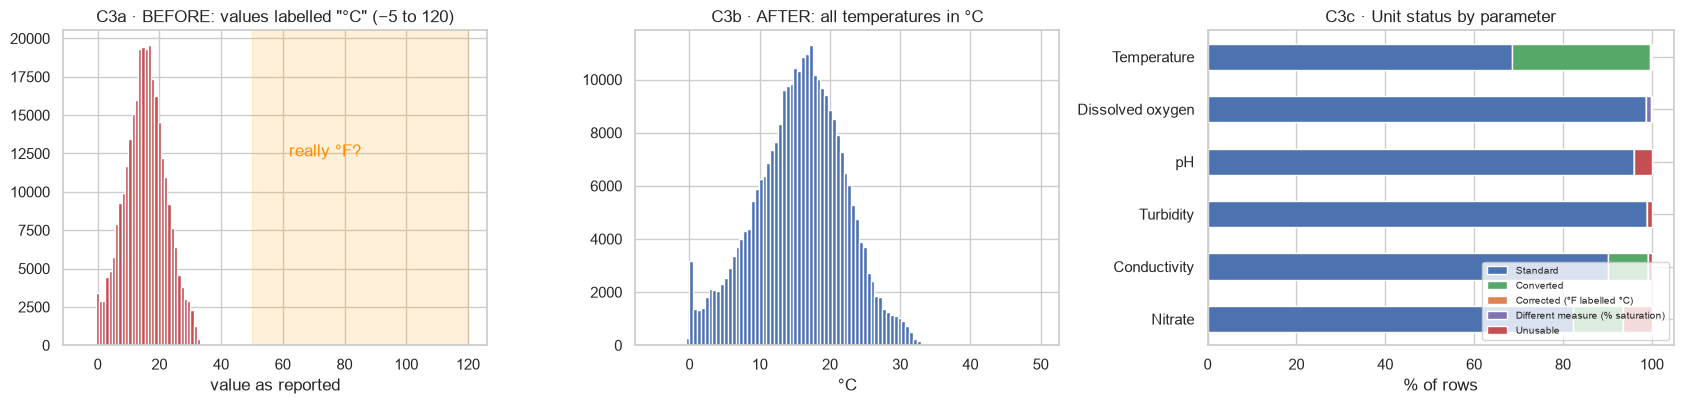

In [3]:
con.execute(r'''
CREATE OR REPLACE MACRO conv(p, u, sp, x) AS CASE
  WHEN x IS NULL THEN NULL
  WHEN p = 'Temperature, water' AND u = 'deg C' AND x BETWEEN 50 AND 120 THEN (x - 32) * 5.0 / 9
  WHEN p = 'Temperature, water' AND u = 'deg C' THEN x
  WHEN p = 'Temperature, water' AND u = 'deg F' THEN (x - 32) * 5.0 / 9
  WHEN p = 'Dissolved oxygen (DO)' AND u IN ('mg/L', 'ppm') THEN x
  WHEN p = 'Dissolved oxygen (DO)' AND u = '%' THEN x
  WHEN p = 'pH' AND (u IS NULL OR u IN ('None', 'std units')) THEN x
  WHEN p = 'Turbidity' AND u IN ('NTU', 'FNU', 'FTU', 'NTRU', 'JTU') THEN x
  WHEN p = 'Conductivity' AND u IN ('uS/cm', 'umho/cm') THEN x
  WHEN p = 'Conductivity' AND u = 'mS/cm' THEN x * 1000
  WHEN p = 'Conductivity' AND u = 'mho/cm' THEN x * 1000000
  WHEN p = 'Conductivity' AND u = 'uS/m' THEN x / 100
  WHEN p = 'Nitrate' AND u IN ('ueq/L', 'umol', 'umol/L') THEN x * 0.014007
  WHEN p = 'Nitrate' AND u IN ('mg/L', 'ppm', 'mg/l as N', 'ug/L', 'mg/l asNO3') THEN
       (CASE WHEN u = 'ug/L' THEN x / 1000 ELSE x END) * (CASE WHEN sp = 'as NO3' OR u = 'mg/l asNO3' THEN 0.2259 ELSE 1 END)
  ELSE NULL END''')
con.execute(r'''
CREATE OR REPLACE MACRO ustatus(p, u, sp, x) AS CASE
  WHEN p = 'Temperature, water' AND u = 'deg C' AND x BETWEEN 50 AND 120 THEN 'Corrected (°F labelled °C)'
  WHEN p = 'Temperature, water' AND u = 'deg C' THEN 'Standard'
  WHEN p = 'Temperature, water' AND u = 'deg F' THEN 'Converted'
  WHEN p = 'Dissolved oxygen (DO)' AND u IN ('mg/L', 'ppm') THEN 'Standard'
  WHEN p = 'Dissolved oxygen (DO)' AND u = '%' THEN 'Different measure (% saturation)'
  WHEN p = 'pH' AND (u IS NULL OR u IN ('None', 'std units')) THEN 'Standard'
  WHEN p = 'Turbidity' AND u IN ('NTU', 'FNU', 'FTU', 'NTRU', 'JTU') THEN 'Standard'
  WHEN p = 'Conductivity' AND u IN ('uS/cm', 'umho/cm') THEN 'Standard'
  WHEN p = 'Conductivity' AND u IN ('mS/cm', 'mho/cm', 'uS/m') THEN 'Converted'
  WHEN p = 'Nitrate' AND u IN ('mg/L', 'ppm', 'mg/l as N') AND coalesce(sp, 'as N') <> 'as NO3' THEN 'Standard'
  WHEN p = 'Nitrate' AND u IN ('mg/L', 'ppm', 'ug/L', 'ueq/L', 'umol', 'umol/L', 'mg/l asNO3') THEN 'Converted'
  ELSE 'Unusable' END''')
con.execute(r'''
CREATE OR REPLACE TABLE v1 AS
WITH p AS (SELECT *,
    regexp_matches(trim(coalesce(val_raw, '')), '^=') AS had_equals,
    TRY_CAST(regexp_replace(trim(val_raw), '^=\s*', '') AS DOUBLE) AS val_num,
    regexp_matches(trim(coalesce(val_raw, '')), '^[<>]') AS censored_txt,
    TRY_CAST(regexp_replace(trim(val_raw), '^[<>]=?\s*', '') AS DOUBLE) AS limit_num
  FROM b)
SELECT *,
  censored_txt OR (val_num IS NULL AND detect_cond IS NOT NULL) AS is_censored,
  ustatus(param, unit_raw, speciation, val_num) AS unit_status,
  conv(param, unit_raw, speciation, CASE WHEN censored_txt THEN NULL ELSE val_num END) AS value_std,
  conv(param, unit_raw, speciation, CASE WHEN censored_txt THEN limit_num END) AS censor_limit,
  CASE param WHEN 'Temperature, water' THEN '°C' WHEN 'Dissolved oxygen (DO)' THEN
            (CASE WHEN unit_raw = '%' THEN '% saturation' ELSE 'mg/L' END)
       WHEN 'pH' THEN 'pH units' WHEN 'Turbidity' THEN 'NTU' WHEN 'Conductivity' THEN 'µS/cm' ELSE 'mg/L as N' END AS unit_std
FROM p''')
con.execute('DROP TABLE b')   # free disk: previous stage no longer needed
us = q('SELECT param, unit_status, count(*) n FROM v1 GROUP BY ALL')
ust = us.pivot_table(index='param', columns='unit_status', values='n', fill_value=0).loc[PARAMS]
ust.index = ust.index.map(SHORT)
display(save_tab(ust, '03_unit_status', index=True))
fixes = q('''SELECT count(*) FILTER (WHERE had_equals AND val_num IS NOT NULL) AS equals_prefix_fixed,
                    count(*) FILTER (WHERE is_censored) AS censored_or_nondetect,
                    count(*) FILTER (WHERE val_raw IS NOT NULL AND val_num IS NULL AND NOT censored_txt) AS text_placeholder
             FROM v1''').T.rename(columns={0: 'Rows'})
display(save_tab(fixes, '02_value_fixes', index=True))

before = q('''SELECT val_num AS v FROM (SELECT val_num FROM v1 WHERE param = 'Temperature, water' AND unit_raw = 'deg C' AND val_num BETWEEN -5 AND 120)
              USING SAMPLE reservoir(300000 ROWS) REPEATABLE (1)''').v
after = q('''SELECT value_std AS v FROM (SELECT value_std FROM v1 WHERE param = 'Temperature, water' AND value_std BETWEEN -5 AND 50
                    AND unit_status <> 'Unusable') USING SAMPLE reservoir(300000 ROWS) REPEATABLE (1)''').v
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2), gridspec_kw={'width_ratios': [1, 1, 1.1]})
axes[0].hist(before, bins=100, color='#C44E52'); axes[0].set(title='C3a · BEFORE: values labelled "°C" (−5 to 120)', xlabel='value as reported')
axes[0].axvspan(50, 120, color='orange', alpha=0.15); axes[0].text(62, axes[0].get_ylim()[1] * 0.6, 'really °F?', color='darkorange')
axes[1].hist(after, bins=100, color='#4C72B0'); axes[1].set(title='C3b · AFTER: all temperatures in °C', xlabel='°C')
ust_pct = ust.div(ust.sum(axis=1), axis=0) * 100
ust_pct[[c for c in ['Standard', 'Converted', 'Corrected (°F labelled °C)', 'Different measure (% saturation)', 'Unusable'] if c in ust_pct]].plot(
    kind='barh', stacked=True, ax=axes[2], color=['#4C72B0', '#55A868', '#DD8452', '#8172B2', '#C44E52'])
axes[2].set(title='C3c · Unit status by parameter', xlabel='% of rows', ylabel=''); axes[2].legend(fontsize=7.5, loc='lower right'); axes[2].invert_yaxis()
save_fig('03_unit_standardisation')

**Why these charts:** the before/after histograms prove the conversion worked (the false 50–120 bump disappears into the normal range), and the stacked bars show how much of each parameter was standard, converted, or unusable.

**🔎 Inference (C3): unit standardisation**
- **885,447 temperatures (31%) were converted from °F**, and **10,848 values labelled "°C" between 50 and 120** were corrected as mislabelled °F. In the *before* histogram these form the separate bump at 50–70; in the *after* histogram they join the normal 0–35 °C range. That the bump vanishes is the visual proof that the correction is right.
- **Conductivity:** 14,270 rows converted (mS/cm ×1000 etc.). **Nitrate:** 5,921 rows converted, mainly "mg/L as NO₃" → "mg/L as N" (×0.2259). This is more than the 2,825 counted in Step 1, because the chemical form (*speciation*) is stored in a separate column that Step 1 did not read.
- **Unusable units stay out of numeric analysis:** pH 29,049 (mostly mV, the raw electrode voltage), turbidity 4,098, nitrate 3,485, temperature 2,991, conductivity 1,371 and DO 685. **9,074 DO rows in % saturation** are kept separately.
- **Value fixes:** 9,708 "=" prefixes repaired, **14,958 censored/non-detect values** kept with their limit, and 22,285 text placeholders left empty.
- **Impact:** about 18% of the data would have been wrong without unit standardisation. This step also explains most of the "impossible" values from Step 1 (see C8): they were unit errors, not bad measurements.

## 4 · Validity flags
Each flag answers one yes/no question. Nothing is deleted.
| Flag | Rule | Why (Step 1 evidence) |
|---|---|---|
| `is_qc` | activity type starts with "Quality Control" | blanks/replicates test equipment, not water (29,108 rows) |
| `is_rejected` | status = Rejected | refused by the data provider (175) |
| `is_suspect` | qualifier contains "SUS" | provider marked it suspect (91,600) |
| `is_provisional` | status = Unreviewed / Raw / Preliminary / Provisional | not final yet; kept but filterable |
| `is_summary` | `StatisticalBaseCode` filled (daily mean/min/max/7DADM) | **different grain** (921,023) |
| `is_logger` | activity type mentions Logger / Continuous / Time Series | automatic sensors |
| `is_duplicate` | 2nd+ copy of the same value inside one **field-visit** activity (same parameter, fraction, statistic, depths, value, unit) | likely duplicate entry (Step 1: 186,497) |
| `is_impossible` | standardised value outside the physical range: temperature −5…50 °C · DO 0…25 mg/L · pH 0…14 · turbidity 0…10,000 NTU (sensors saturate near 4,000) · conductivity 0…200,000 µS/cm (seawater ≈ 55,000; even salt lakes stay below 200,000) · nitrate 0…100 mg/L as N | physically impossible |

In [4]:
con.execute('''
CREATE OR REPLACE TABLE v2a AS SELECT *,
  act_type ILIKE 'Quality Control%' AS is_qc,
  coalesce(status = 'Rejected', false) AS is_rejected,
  coalesce(qualifier, '') ILIKE '%SUS%' AS is_suspect,
  coalesce(status IN ('Unreviewed', 'Raw', 'Preliminary', 'Provisional'), false) AS is_provisional,
  stat IS NOT NULL AS is_summary,
  (act_type ILIKE '%Logger%' OR act_type ILIKE '%Continuous%' OR act_type ILIKE '%Time Series%') AS is_logger,
  CASE WHEN value_std IS NULL OR unit_status IN ('Unusable', 'Different measure (% saturation)') THEN false
       WHEN param = 'Temperature, water' THEN value_std NOT BETWEEN -5 AND 50
       WHEN param = 'Dissolved oxygen (DO)' THEN value_std NOT BETWEEN 0 AND 25
       WHEN param = 'pH' THEN value_std NOT BETWEEN 0 AND 14
       WHEN param = 'Turbidity' THEN value_std NOT BETWEEN 0 AND 10000
       WHEN param = 'Conductivity' THEN value_std NOT BETWEEN 0 AND 200000
       WHEN param = 'Nitrate' THEN value_std NOT BETWEEN 0 AND 100
       ELSE value_std < 0 END AS is_impossible
FROM v1''')
con.execute('DROP TABLE v1')
con.execute('''
CREATE OR REPLACE TABLE v2 AS SELECT *,
  (NOT is_logger) AND row_number() OVER (PARTITION BY act_id, param, fraction_raw, stat, act_depth, res_depth_raw, val_raw, unit_raw
                                         ORDER BY result_id) > 1 AS is_duplicate
FROM v2a''')
con.execute('DROP TABLE v2a')
flags = q('''SELECT sum(is_qc::INT) qc, sum(is_rejected::INT) rejected, sum(is_suspect::INT) suspect, sum(is_provisional::INT) provisional,
                    sum(is_summary::INT) summary_grain, sum(is_logger::INT) logger, sum(is_duplicate::INT) duplicate, sum(is_impossible::INT) impossible
             FROM v2''').T.rename(columns={0: 'Rows'})
flags['% of rows'] = (flags.Rows / N_RAW * 100).round(3)
display(save_tab(flags, '04_validity_flags', index=True))

,Rows,% of rows
qc,29108.0,0.587
rejected,175.0,0.004
suspect,91600.0,1.847
provisional,92644.0,1.868
summary_grain,921023.0,18.576
logger,1017383.0,20.519
duplicate,186497.0,3.761
impossible,6213.0,0.125


## 5 · Time cleaning
| New column | Rule | Why |
|---|---|---|
| `time_clean` | `00:00:00` in a **field visit** becomes unknown; loggers and summaries keep midnight | Step 1: field-visit midnights are placeholders; logger midnights are real readings |
| `hour` | hour of `time_clean` | |
| `time_band` (observed) | Night 0–5 · Morning 6–11 · Afternoon 12–17 · Evening 18–23 · **Whole day** for summary rows · empty if unknown | the empty ones are imputed in section 11 |
| `ts_local` | date + time (12:00 used when the time is unknown, with `time_known = false`) | gives every event an order, needed for the real-time replay |
| `ts_utc` | local time converted with the time-zone offset (EST −5, CDT −5, PDT −7 …) | compares events across time zones; empty when time or zone is unknown |

In [5]:
con.execute('''
CREATE OR REPLACE TABLE v3 AS
WITH t AS (SELECT *,
    CASE WHEN tm_raw = '00:00:00' AND NOT is_logger AND NOT is_summary THEN NULL ELSE tm_raw END AS time_clean,
    CASE tz WHEN 'EST' THEN -5 WHEN 'EDT' THEN -4 WHEN 'CST' THEN -6 WHEN 'CDT' THEN -5 WHEN 'MST' THEN -7 WHEN 'MDT' THEN -6
            WHEN 'PST' THEN -8 WHEN 'PDT' THEN -7 WHEN 'AKST' THEN -9 WHEN 'AKDT' THEN -8 WHEN 'HST' THEN -10 WHEN 'HAST' THEN -10
            WHEN 'AST' THEN -4 WHEN 'UTC' THEN 0 END AS utc_offset
  FROM v2)
SELECT *,
  TRY_CAST(substr(time_clean, 1, 2) AS INT) AS hour,
  CASE WHEN is_summary THEN 'Whole day'
       WHEN TRY_CAST(substr(time_clean, 1, 2) AS INT) IS NULL THEN NULL
       WHEN TRY_CAST(substr(time_clean, 1, 2) AS INT) < 6 THEN 'Night'
       WHEN TRY_CAST(substr(time_clean, 1, 2) AS INT) < 12 THEN 'Morning'
       WHEN TRY_CAST(substr(time_clean, 1, 2) AS INT) < 18 THEN 'Afternoon' ELSE 'Evening' END AS time_band_obs,
  TRY_CAST(time_clean AS TIME) IS NOT NULL AS time_known,
  dt + coalesce(TRY_CAST(time_clean AS TIME), TIME '12:00:00') AS ts_local,
  CASE WHEN TRY_CAST(time_clean AS TIME) IS NOT NULL AND utc_offset IS NOT NULL
       THEN dt + TRY_CAST(time_clean AS TIME) - to_hours(utc_offset) END AS ts_utc
FROM t''')
con.execute('DROP TABLE v2')
tb = q("SELECT coalesce(time_band_obs, '(unknown → impute)') AS time_band, count(*) n FROM v3 GROUP BY 1 ORDER BY n DESC")
tb['pct'] = (tb.n / N_RAW * 100).round(2); display(save_tab(tb, '05_time_band_observed'))
print(q("SELECT count(*) FILTER (WHERE ts_utc IS NOT NULL) AS rows_with_utc, min(ts_local) AS first_event, max(ts_local) AS last_event FROM v3"))

,time_band,n,pct
0,Morning,1719584,34.68
1,(unknown → impute),1083510,21.85
2,Afternoon,992707,20.02
3,Whole day,921023,18.58
4,Night,157604,3.18
5,Evening,83810,1.69


   rows_with_utc first_event          last_event
0        3525385  2024-01-01 2025-12-31 16:00:00


## 6 · Geography: clean coordinates → US state → Census region
**Coordinate rules (Step 1, section 14):** set to missing when the latitude or longitude is 0, near (0°, 0°), out of range, or has a **positive longitude north of 20°N** (a missing minus sign). Wrong-sign points are listed as `flip_candidate` for transparency but **not auto-corrected**.

**State lookup:** each site's median coordinate is tested against the official **US state boundary polygons** (`data/reference/us-states.json`, 50 states + DC + Puerto Rico) with a *point-in-polygon* test (is the dot inside the shape?). The boundary file is simplified, so a site on the coast or in an estuary can fall just outside its state. Those are matched to the **nearest state boundary within 0.25° (~25 km)**, recorded as `state_match = 'nearest'`.

**Region:** states are grouped into the 4 official **US Census Bureau regions** (Northeast, Midwest, South, West), plus *Territory* and *Unknown*.
This gives the warehouse a real **Region → State → Site** hierarchy.

,sites,pct
state_match,,
inside,45654,90.45
nearest,3103,6.15
none,1719,3.41


,region,sites,rows,pct_rows
0,Midwest,12628,2025349,40.85
1,West,9147,1550412,31.27
2,South,21163,1061765,21.41
3,Northeast,5785,293702,5.92
4,Unknown,1582,14067,0.28
5,Territory,171,12943,0.26


States/areas with data: 54


,state,region,sites,rows
0,Wisconsin,Midwest,2743,1472160
1,Oregon,West,1315,714155
2,Washington,West,1750,526367
3,Florida,South,11061,336792
4,Minnesota,Midwest,5243,327893
5,Virginia,South,1972,131520
6,Alabama,South,1112,127072
7,Connecticut,Northeast,653,96414
8,Georgia,South,481,85959
9,Utah,West,884,74925


Flip candidates (positive longitude, kept as missing): {'n': 1058, 's': 20}


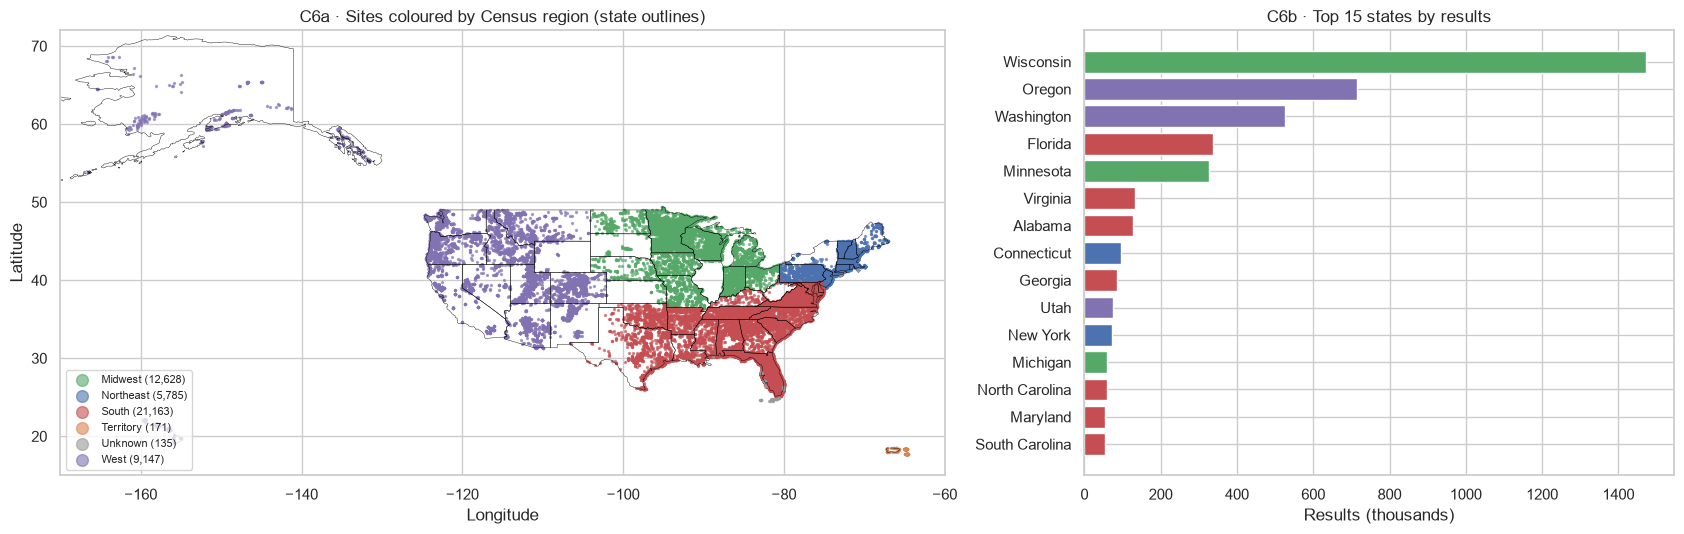

In [6]:
con.execute('''
CREATE OR REPLACE TABLE v4 AS SELECT *,
  (lon_raw > 0 AND lat_raw > 20) AS flip_candidate,
  CASE WHEN lat_raw IS NULL OR lon_raw IS NULL OR lat_raw = 0 OR lon_raw = 0 OR (abs(lat_raw) < 2 AND abs(lon_raw) < 2)
         OR lat_raw NOT BETWEEN -90 AND 90 OR lon_raw NOT BETWEEN -180 AND 180 OR (lon_raw > 0 AND lat_raw > 20) THEN NULL ELSE lat_raw END AS lat,
  CASE WHEN lat_raw IS NULL OR lon_raw IS NULL OR lat_raw = 0 OR lon_raw = 0 OR (abs(lat_raw) < 2 AND abs(lon_raw) < 2)
         OR lat_raw NOT BETWEEN -90 AND 90 OR lon_raw NOT BETWEEN -180 AND 180 OR (lon_raw > 0 AND lat_raw > 20) THEN NULL ELSE lon_raw END AS lon
FROM v3''')
con.execute('DROP TABLE v3')
sites = q('SELECT site, median(lat) AS lat, median(lon) AS lon, count(*) AS n FROM v4 GROUP BY site')

gj = json.load(open(STATES))
polys, verts, vstate = [], [], []
for f in gj['features']:
    name = f['properties']['name']; g = f['geometry']
    rings = [g['coordinates']] if g['type'] == 'Polygon' else g['coordinates']
    for poly in rings:
        ring = np.array(poly[0]); polys.append((name, MplPath(ring), ring[:, 0].min(), ring[:, 0].max(), ring[:, 1].min(), ring[:, 1].max()))
        verts.append(ring); vstate += [name] * len(ring)
ok = sites.lat.notna()
pts = sites.loc[ok, ['lon', 'lat']].to_numpy()
state = np.array([None] * len(pts), dtype=object)
for name, path, x0, x1, y0, y1 in polys:
    cand = (state == None) & (pts[:, 0] >= x0) & (pts[:, 0] <= x1) & (pts[:, 1] >= y0) & (pts[:, 1] <= y1)
    if cand.any():
        inside = path.contains_points(pts[cand]); idx = np.where(cand)[0][inside]; state[idx] = name
match = np.where(state != None, 'inside', None).astype(object)
tree = cKDTree(np.vstack(verts)); vstate = np.array(vstate)
miss_i = np.where(state == None)[0]
d, j = tree.query(pts[miss_i])
near = d <= 0.25
state[miss_i[near]] = vstate[j[near]]; match[miss_i[near]] = 'nearest'
sites.loc[ok, 'state'] = state; sites.loc[ok, 'state_match'] = match
sites['state_match'] = sites.state_match.fillna('none')

REGION = {**{s: 'Northeast' for s in ['Connecticut', 'Maine', 'Massachusetts', 'New Hampshire', 'Rhode Island', 'Vermont', 'New Jersey', 'New York', 'Pennsylvania']},
          **{s: 'Midwest' for s in ['Illinois', 'Indiana', 'Michigan', 'Ohio', 'Wisconsin', 'Iowa', 'Kansas', 'Minnesota', 'Missouri', 'Nebraska', 'North Dakota', 'South Dakota']},
          **{s: 'South' for s in ['Delaware', 'Florida', 'Georgia', 'Maryland', 'North Carolina', 'South Carolina', 'Virginia', 'District of Columbia', 'West Virginia',
                                  'Alabama', 'Kentucky', 'Mississippi', 'Tennessee', 'Arkansas', 'Louisiana', 'Oklahoma', 'Texas']},
          **{s: 'West' for s in ['Arizona', 'Colorado', 'Idaho', 'Montana', 'Nevada', 'New Mexico', 'Utah', 'Wyoming', 'Alaska', 'California', 'Hawaii', 'Oregon', 'Washington']},
          'Puerto Rico': 'Territory'}
def region(r):
    if isinstance(r.state, str): return REGION[r.state]
    if pd.notna(r.lat) and ((r.lon > 100) or (r.lat < 20 and r.lon > -70)): return 'Territory'
    return 'Unknown'
sites['region'] = sites.apply(region, axis=1)
sites['state'] = sites.state.where(sites.state.notna(), np.where(sites.region == 'Territory', 'Other territory', 'Unknown'))
con.register('sites_df', sites[['site', 'state', 'region', 'state_match']])
con.execute('CREATE OR REPLACE TABLE site_geo AS SELECT * FROM sites_df')
con.execute('CREATE OR REPLACE TABLE v4 AS SELECT v4.*, g.state, g.region, g.state_match FROM v4 LEFT JOIN site_geo g USING (site)')

sm = sites.state_match.value_counts().rename('sites').to_frame(); sm['pct'] = (sm.sites / len(sites) * 100).round(2)
display(save_tab(sm, '06_state_match', index=True))
rg = q('SELECT region, count(DISTINCT site) AS sites, count(*) AS rows FROM v4 GROUP BY 1 ORDER BY rows DESC')
rg['pct_rows'] = (rg.rows / N_RAW * 100).round(2); display(save_tab(rg, '06_region_summary'))
st = q('SELECT state, region, count(DISTINCT site) AS sites, count(*) AS rows FROM v4 GROUP BY ALL ORDER BY rows DESC')
save_tab(st, '06_state_summary'); print(f'States/areas with data: {st.state.nunique()}'); display(st.head(12))
print('Flip candidates (positive longitude, kept as missing):', q('SELECT count(*) n, count(DISTINCT site) s FROM v4 WHERE flip_candidate').iloc[0].to_dict())

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={'width_ratios': [1.5, 1]})
pal = {'Northeast': '#4C72B0', 'Midwest': '#55A868', 'South': '#C44E52', 'West': '#8172B2', 'Territory': '#DD8452', 'Unknown': '#999999'}
for rgn, d in sites[sites.lat.notna()].groupby('region'):
    axes[0].scatter(d.lon, d.lat, s=2, color=pal[rgn], label=f'{rgn} ({len(d):,})', alpha=0.6)
for name, path, *_ in polys:
    v = path.vertices; axes[0].plot(v[:, 0], v[:, 1], color='black', lw=0.3)
axes[0].set(xlim=(-170, -60), ylim=(15, 72), title='C6a · Sites coloured by Census region (state outlines)', xlabel='Longitude', ylabel='Latitude')
axes[0].legend(markerscale=6, fontsize=8, loc='lower left')
top = st.head(15).iloc[::-1]
axes[1].barh(top.state, top.rows / 1e3, color=[pal[r] for r in top.region])
axes[1].set(title='C6b · Top 15 states by results', xlabel='Results (thousands)')
save_fig('06_geography')

**Why these charts:** the map checks that the state assignment is right (dots should sit inside their state outlines, coloured by region), and the bar chart shows where the data actually comes from.

**🔎 Inference (C6): geography → state → region**
- **48,757 of 50,476 sites (96.6%) now have a US state**: **90.5%** fall inside a state boundary and **6.2%** were matched to the nearest boundary within ~25 km (coastal and estuary sites that fall just outside the simplified outline). Only **1,719 sites (3.4%)** remain *Unknown*, almost all of them sites with no usable coordinates.
- The data covers **54 states/areas** (50 states + DC + Puerto Rico + other territories), but it is **highly concentrated**:
  - **Wisconsin alone has 1.47M results (29.7%)**, then Oregon (714K), Washington (526K), Florida (337K) and Minnesota (328K).
  - **Florida has the most sites (11,061)** but far fewer results per site: many sites sampled a few times, versus Wisconsin's few intensive sites.
- **By Census region:** Midwest 40.9% of results, West 31.3%, South 21.4%, Northeast 5.9%. The **South has the most sites (21,163)** but only a fifth of the results.
- The 20 wrong-sign sites (1,058 rows) stay *Unknown* and are listed as `flip_candidate`, so they can be corrected later if the Station file confirms them.
- **Impact:** the warehouse gets a real **Region → State → Site** hierarchy for drill-down. Because volume is so uneven, regional comparisons must use **rates per result**, never raw totals (otherwise "Wisconsin" simply means "most measured").

## 7 · Outliers: flag, don't delete
**Rule:** an *extreme outlier* lies beyond **3 × IQR** from the middle 50% of values. It is computed only on usable rows (not QC, rejected, duplicate, summary, censored, unusable unit or impossible).
- **Temperature, DO, pH** are roughly symmetric, so the IQR is computed on the values themselves.
- **Turbidity, conductivity, nitrate** are strongly right-skewed (Step 1), so the IQR is computed on **log10(value)**. On the raw scale the rule wrongly flagged about 7% of real high values (storms, estuaries). On the log scale it flags only values that are extreme even for a skewed parameter.

In [7]:
BASE = ("NOT is_qc AND NOT is_rejected AND NOT is_duplicate AND NOT is_summary AND NOT is_censored AND NOT is_impossible "
        "AND value_std IS NOT NULL AND unit_status NOT IN ('Unusable', 'Different measure (% saturation)')")
LOGP = ('Turbidity', 'Conductivity', 'Nitrate')
fences = []
for p in PARAMS:
    expr = 'log10(value_std)' if p in LOGP else 'value_std'
    cond = f"param = '{p}' AND {BASE}" + (' AND value_std > 0' if p in LOGP else '')
    r = q(f"SELECT quantile_cont({expr}, 0.25) q1, quantile_cont({expr}, 0.75) q3 FROM v4 WHERE {cond}").iloc[0]
    iqr = r.q3 - r.q1; lo, hi = r.q1 - 3 * iqr, r.q3 + 3 * iqr
    fences.append({'param': p, 'scale': 'log10' if p in LOGP else 'linear', 'q1': r.q1, 'q3': r.q3, 'low_fence': lo, 'high_fence': hi,
                   'low_fence_value': 10 ** lo if p in LOGP else lo, 'high_fence_value': 10 ** hi if p in LOGP else hi})
fz = pd.DataFrame(fences); con.register('fz', fz)
con.execute(f'''
CREATE OR REPLACE TABLE v5 AS SELECT v4.*,
  CASE WHEN NOT ({BASE}) THEN false
       WHEN fz.scale = 'log10' AND v4.value_std > 0 THEN log10(v4.value_std) NOT BETWEEN fz.low_fence AND fz.high_fence
       WHEN fz.scale = 'log10' THEN false
       ELSE v4.value_std NOT BETWEEN fz.low_fence AND fz.high_fence END AS is_extreme_outlier
FROM v4 LEFT JOIN fz USING (param)''')
con.execute('DROP TABLE v4')
oc = q(f"SELECT param, count(*) FILTER (WHERE {BASE}) AS usable, sum(is_extreme_outlier::INT) AS extreme FROM v5 GROUP BY param")
oc = fz[['param', 'scale', 'low_fence_value', 'high_fence_value']].merge(oc, on='param')
oc['% extreme'] = (oc.extreme / oc.usable * 100).round(2); oc['param'] = oc.param.map(SHORT)
display(save_tab(oc.round(3), '07_outlier_fences'))

,param,scale,low_fence_value,high_fence_value,usable,extreme,% extreme
0,Temperature,linear,-10.610,44.970,1912496,25.0,0.00
1,Dissolved oxygen,linear,-5.460,21.280,690253,113.0,0.02
2,pH,linear,4.340,11.060,658303,2254.0,0.34
3,Turbidity,log10,0.005,3093.867,336418,1154.0,0.34
4,Conductivity,log10,0.252,88148.550,131427,742.0,0.56
5,Nitrate,log10,0.000,3309.392,43379,0.0,0.00


## 8 · One `ExclusionReason` per row, and reconciliation
Each row gets **at most one** main reason, checked in this priority order (the first rule that applies wins):
1. Quality-control record → 2. Rejected → 3. Duplicate copy → 4. Summary statistic (separate grain) → 5. Censored / non-detect → 6. No numeric value → 7. Unusable unit → 8. DO % saturation (different measure) → 9. Physically impossible → 10. Suspect (provider flag)

A row with **no reason** is **analysis-ready**. Outliers and provisional results stay analysis-ready but carry their flags.
**Reconciliation checks:** raw = curated (nothing removed), and curated = analysis-ready + Σ excluded.

,reason,rows,pct
0,✔ Analysis-ready,3772033,76.076
1,Summary statistic (separate grain),908630,18.326
2,Duplicate copy,186285,3.757
3,Unusable unit,32085,0.647
4,Quality-control record,29108,0.587
5,Censored / non-detect,13030,0.263
6,DO % saturation (different measure),8649,0.174
7,Physically impossible,5014,0.101
8,No numeric value,3003,0.061
9,Suspect (provider flag),243,0.005


,Rows,% of raw
1. Raw rows in file,4958238,100.00
2. Rows removed,0,0.00
3. Curated rows (1 − 2),4958238,100.00
"4. Excluded from analysis (flagged, kept)",1186205,23.92
5. Analysis-ready (3 − 4),3772033,76.08


✔ Reconciliation passed: raw = curated, and curated = analysis-ready + Σ excluded


,param,rows,ready,% ready
0,Nitrate,53297,43379.0,81.4
1,Turbidity,372214,336418.0,90.4
2,pH,740621,658268.0,88.9
3,Conductivity,156912,131417.0,83.8
4,Dissolved oxygen,773167,690164.0,89.3
5,Temperature,2862027,1912387.0,66.8


C:\Users\sansk\AppData\Local\Temp\ipykernel_28916\1328427062.py:32: UserWarning: Glyph 10004 (\N{HEAVY CHECK MARK}) missing from font(s) Arial.
  def save_fig(name): plt.tight_layout(); plt.savefig(FIG / f'C{name}.png', dpi=130, bbox_inches='tight'); plt.show()


C:\Users\sansk\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10004 (\N{HEAVY CHECK MARK}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


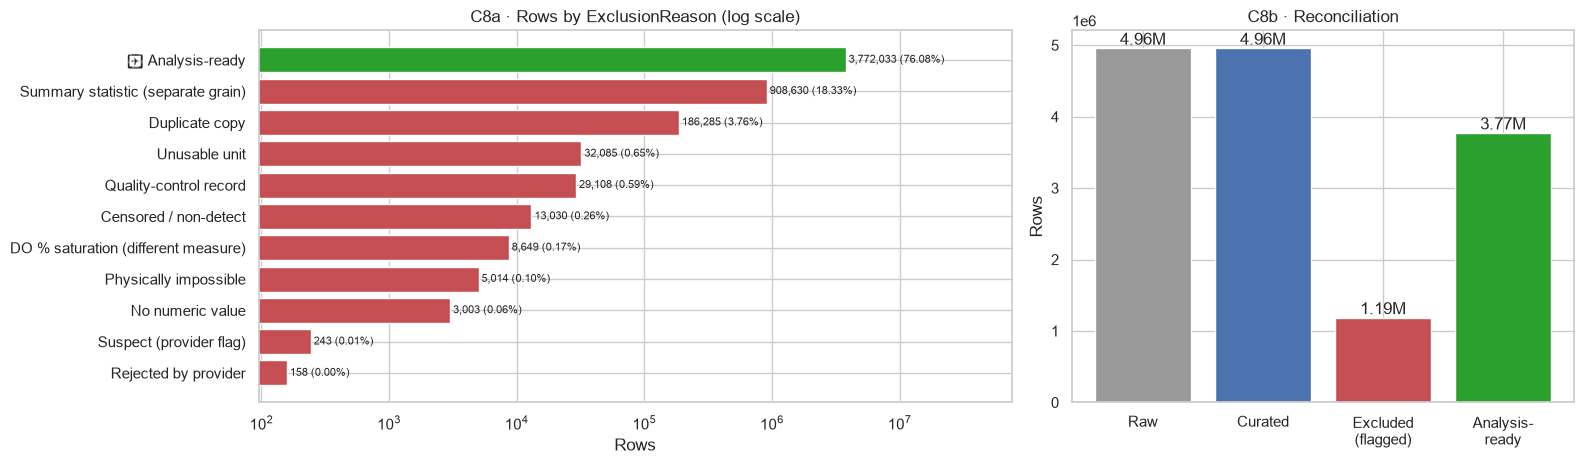

In [8]:
con.execute('''
CREATE OR REPLACE TABLE v6 AS SELECT *,
  CASE WHEN is_qc THEN 'Quality-control record' WHEN is_rejected THEN 'Rejected by provider'
       WHEN is_duplicate THEN 'Duplicate copy' WHEN is_summary THEN 'Summary statistic (separate grain)'
       WHEN is_censored THEN 'Censored / non-detect' WHEN val_num IS NULL THEN 'No numeric value'
       WHEN unit_status = 'Unusable' THEN 'Unusable unit' WHEN unit_status = 'Different measure (% saturation)' THEN 'DO % saturation (different measure)'
       WHEN is_impossible THEN 'Physically impossible' WHEN is_suspect THEN 'Suspect (provider flag)' END AS exclusion_reason
FROM v5''')
con.execute('DROP TABLE v5')
con.execute('ALTER TABLE v6 ADD COLUMN analysis_ready BOOLEAN')
con.execute('UPDATE v6 SET analysis_ready = exclusion_reason IS NULL')
ex = q("SELECT coalesce(exclusion_reason, '✔ Analysis-ready') AS reason, count(*) AS rows FROM v6 GROUP BY 1 ORDER BY rows DESC")
ex['pct'] = (ex.rows / N_RAW * 100).round(3); display(save_tab(ex, '08_exclusion_reasons'))
n_cur = q('SELECT count(*) n FROM v6').n[0]; n_ready = int(ex.loc[ex.reason == '✔ Analysis-ready', 'rows'].sum())
rec = pd.DataFrame({'Rows': {'1. Raw rows in file': N_RAW, '2. Rows removed': N_RAW - n_cur, '3. Curated rows (1 − 2)': n_cur,
                             '4. Excluded from analysis (flagged, kept)': n_cur - n_ready, '5. Analysis-ready (3 − 4)': n_ready}})
rec['% of raw'] = (rec.Rows / N_RAW * 100).round(2); display(save_tab(rec, '08_reconciliation', index=True))
assert n_cur == N_RAW and ex.rows.sum() == n_cur, 'Reconciliation failed'
print('✔ Reconciliation passed: raw = curated, and curated = analysis-ready + Σ excluded')
by_p = q("SELECT param, count(*) AS rows, sum(analysis_ready::INT) AS ready FROM v6 GROUP BY param")
by_p['% ready'] = (by_p.ready / by_p.rows * 100).round(1); by_p['param'] = by_p.param.map(SHORT)
display(save_tab(by_p, '08_ready_by_parameter'))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={'width_ratios': [1.5, 1]})
d = ex.iloc[::-1]
axes[0].barh(d.reason, d.rows, color=['#2ca02c' if r.startswith('✔') else '#C44E52' for r in d.reason]); axes[0].set_xscale('log')
for i, (n_, p_) in enumerate(zip(d.rows, d.pct)): axes[0].text(n_, i, f' {n_:,} ({p_:.2f}%)', va='center', fontsize=8)
axes[0].set(title='C8a · Rows by ExclusionReason (log scale)', xlabel='Rows'); axes[0].set_xlim(right=d.rows.max() * 20)
axes[1].bar(['Raw', 'Curated', 'Excluded\n(flagged)', 'Analysis-\nready'], [N_RAW, n_cur, n_cur - n_ready, n_ready], color=['#999999', '#4C72B0', '#C44E52', '#2ca02c'])
for i, v_ in enumerate([N_RAW, n_cur, n_cur - n_ready, n_ready]): axes[1].text(i, v_, f'{v_/1e6:.2f}M', ha='center', va='bottom')
axes[1].set(title='C8b · Reconciliation', ylabel='Rows')
save_fig('08_exclusion_reconciliation')

**Why these charts:** the log-scale bars show every exclusion reason, even the tiny ones; the reconciliation bars prove visually that nothing disappeared.

**🔎 Inference (C8): exclusion reasons and reconciliation**
- **Reconciliation passed exactly:** raw 4,958,238 = curated 4,958,238 (**0 rows deleted**) = **3,772,033 analysis-ready (76.1%)** + **1,186,205 excluded with a reason**.
- **The largest exclusion is not an error:** **908,630 daily summaries** (mean/min/max) are a different grain and will feed a separate summary fact. The real quality exclusions are much smaller:
  - duplicates 186,285
  - unusable units 32,085
  - QC records 29,108
  - censored 13,030
  - physically impossible 5,014
  - rejected 158
- **Physically impossible values dropped from 14,780 (Step 1, raw units) to about 5,014 after unit standardisation.** Most "impossible" values were really **unit mistakes** that are now fixed, not bad measurements.
- **Only 243 rows are excluded *because* they are suspect**, although 91,600 carry the suspect flag. The rest were already excluded for a higher-priority reason (mostly daily summaries), which shows why one reason per row avoids double-counting.
- **Temperature has the lowest analysis-ready share (66.8%)** because most daily summaries are temperatures (logger programmes report daily mean/min/max). The other parameters are 81–90% analysis-ready.
- **Impact:** 3.77M high-quality single readings remain, which is plenty for the warehouse and models, and every excluded row can be explained.

## 9 · Derived attributes and documented thresholds
The brief requires every derived attribute and threshold to be documented and **not presented as an original field**.

| Attribute | Rule |
|---|---|
| Year, Quarter, Month, DayOfWeek | from the sampling date |
| **Season** | Winter = Dec–Feb · Spring = Mar–May · Summer = Jun–Aug · Autumn = Sep–Nov (meteorological, Northern Hemisphere) |
| **ParameterGroup** | Physical = temperature, turbidity, conductivity · Chemical = pH, dissolved oxygen · Nutrient = nitrate |
| **SampleTypeGroup** | Quality control · Logger / continuous · Lab sample · Field measurement · Unknown |
| **ResultBand** | Very Low / Low / Normal / High / Very High, using the bands below |
| **ExceedanceFlag** | 1 if the value breaks the exceedance threshold (analysis-ready rows only) |
| **HighRiskFlag** | 1 if the value breaks the stricter high-risk threshold |

| Parameter | Very Low | Low | Normal | High | Very High | **Exceedance** | **High risk** | Source |
|---|---|---|---|---|---|---|---|---|
| Dissolved oxygen (mg/L) | < 2 | 2–5 | 5–12 | 12–15 | > 15 | **< 5** | **< 2** | EPA aquatic-life DO criteria (5 mg/L warm-water; < 2 hypoxia) |
| pH | < 6.0 | 6.0–6.5 | 6.5–9.0 | 9.0–9.5 | > 9.5 | **< 6.5 or > 9.0** | **< 6.0 or > 9.5** | EPA national criterion 6.5–9; risk margin = project |
| Nitrate (mg/L as N) | – | < 0.1 | 0.1–3 | 3–10 | > 10 | **> 10** | **> 20** | EPA drinking-water MCL 10 mg/L; 20 = project |
| Temperature (°C) | – | < 10 | 10–20 | 20–28 | > 28 | **> 28** | **> 32** | *Project threshold* (aquatic-life heat stress) |
| Turbidity (NTU) | – | < 1 | 1–25 | 25–100 | > 100 | **> 25** | **> 100** | *Project threshold* |
| Conductivity (µS/cm) | – | < 50 | 50–1,500 | 1,500–3,000 | > 3,000 | **> 1,500** | **> 3,000** | *Project threshold* |

*Note:* conductivity and turbidity have no national EPA numeric criterion; the project thresholds are labelled as such. Ocean/estuary sites naturally exceed the conductivity threshold, so conductivity exceedances must be read together with water type.

,ready,exceed_pct,high_risk_pct,exceedances,high_risk
param,,,,,
Temperature,1912387,3.38,0.23,64652.0,4308.0
Dissolved oxygen,690164,18.22,8.56,125770.0,59111.0
pH,658268,8.72,2.99,57404.0,19680.0
Turbidity,336418,10.50,2.48,35339.0,8353.0
Conductivity,131417,6.08,4.46,7985.0,5858.0
Nitrate,43379,3.28,1.02,1421.0,442.0


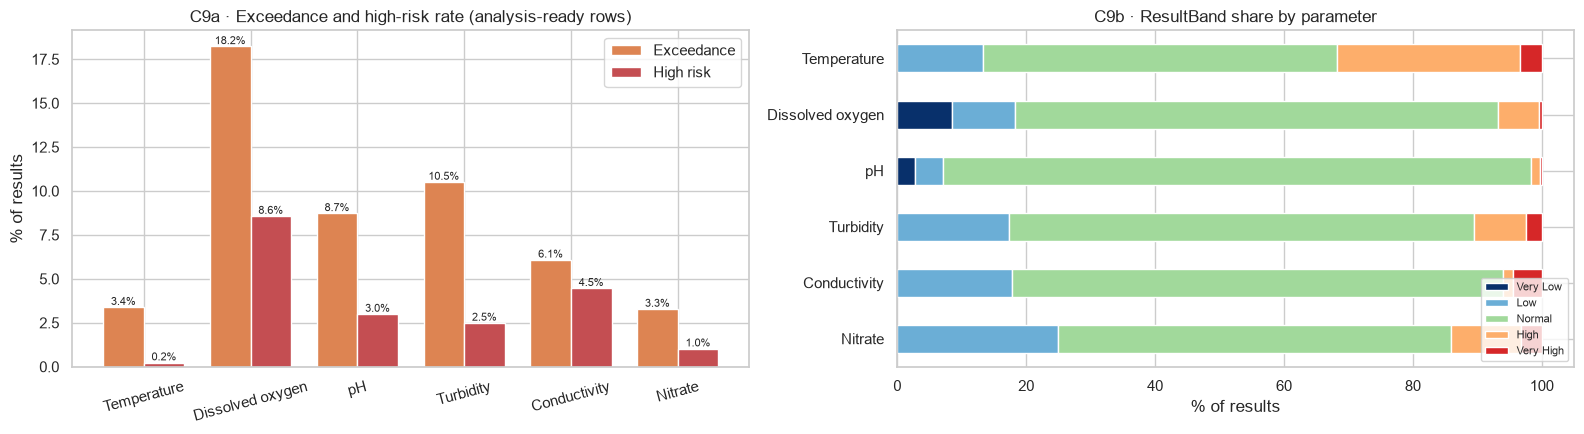

In [9]:
con.execute('''
CREATE OR REPLACE TABLE v7 AS SELECT *,
  year(dt) AS year, quarter(dt) AS quarter, month(dt) AS month, dayname(dt) AS day_of_week,
  CASE WHEN month(dt) IN (12, 1, 2) THEN 'Winter' WHEN month(dt) IN (3, 4, 5) THEN 'Spring'
       WHEN month(dt) IN (6, 7, 8) THEN 'Summer' ELSE 'Autumn' END AS season,
  CASE param WHEN 'pH' THEN 'Chemical' WHEN 'Dissolved oxygen (DO)' THEN 'Chemical' WHEN 'Nitrate' THEN 'Nutrient' ELSE 'Physical' END AS parameter_group,
  CASE WHEN is_qc THEN 'Quality control' WHEN is_logger THEN 'Logger / continuous' WHEN act_type ILIKE 'Sample%' THEN 'Lab sample'
       WHEN act_type ILIKE 'Field%' THEN 'Field measurement' ELSE 'Unknown' END AS sample_type_group,
  CASE WHEN NOT analysis_ready THEN NULL
    WHEN param = 'Dissolved oxygen (DO)' THEN CASE WHEN value_std < 2 THEN 'Very Low' WHEN value_std < 5 THEN 'Low' WHEN value_std <= 12 THEN 'Normal' WHEN value_std <= 15 THEN 'High' ELSE 'Very High' END
    WHEN param = 'pH' THEN CASE WHEN value_std < 6 THEN 'Very Low' WHEN value_std < 6.5 THEN 'Low' WHEN value_std <= 9 THEN 'Normal' WHEN value_std <= 9.5 THEN 'High' ELSE 'Very High' END
    WHEN param = 'Nitrate' THEN CASE WHEN value_std < 0.1 THEN 'Low' WHEN value_std <= 3 THEN 'Normal' WHEN value_std <= 10 THEN 'High' ELSE 'Very High' END
    WHEN param = 'Temperature, water' THEN CASE WHEN value_std < 10 THEN 'Low' WHEN value_std <= 20 THEN 'Normal' WHEN value_std <= 28 THEN 'High' ELSE 'Very High' END
    WHEN param = 'Turbidity' THEN CASE WHEN value_std < 1 THEN 'Low' WHEN value_std <= 25 THEN 'Normal' WHEN value_std <= 100 THEN 'High' ELSE 'Very High' END
    WHEN param = 'Conductivity' THEN CASE WHEN value_std < 50 THEN 'Low' WHEN value_std <= 1500 THEN 'Normal' WHEN value_std <= 3000 THEN 'High' ELSE 'Very High' END
  END AS result_band,
  CASE WHEN NOT analysis_ready THEN NULL ELSE (CASE param
    WHEN 'Dissolved oxygen (DO)' THEN value_std < 5 WHEN 'pH' THEN value_std < 6.5 OR value_std > 9
    WHEN 'Nitrate' THEN value_std > 10 WHEN 'Temperature, water' THEN value_std > 28
    WHEN 'Turbidity' THEN value_std > 25 WHEN 'Conductivity' THEN value_std > 1500 END)::INT END AS exceedance_flag,
  CASE WHEN NOT analysis_ready THEN NULL ELSE (CASE param
    WHEN 'Dissolved oxygen (DO)' THEN value_std < 2 WHEN 'pH' THEN value_std < 6 OR value_std > 9.5
    WHEN 'Nitrate' THEN value_std > 20 WHEN 'Temperature, water' THEN value_std > 32
    WHEN 'Turbidity' THEN value_std > 100 WHEN 'Conductivity' THEN value_std > 3000 END)::INT END AS high_risk_flag
FROM v6''')
con.execute('DROP TABLE v6')
rates = q('''SELECT param, count(*) AS ready, avg(exceedance_flag) * 100 AS exceed_pct, avg(high_risk_flag) * 100 AS high_risk_pct,
                    sum(exceedance_flag) AS exceedances, sum(high_risk_flag) AS high_risk
             FROM v7 WHERE analysis_ready GROUP BY param''').set_index('param').loc[PARAMS]
rates.index = rates.index.map(SHORT); display(save_tab(rates.round(2), '09_exceedance_rates', index=True))
bands = q('SELECT param, result_band, count(*) n FROM v7 WHERE analysis_ready GROUP BY ALL')
bp = bands.pivot_table(index='param', columns='result_band', values='n', fill_value=0).loc[PARAMS]
bp = bp[[c for c in ['Very Low', 'Low', 'Normal', 'High', 'Very High'] if c in bp]]; bp.index = bp.index.map(SHORT)
save_tab(bp, '09_result_bands', index=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
x = np.arange(len(rates)); w = 0.38
b1 = axes[0].bar(x - w / 2, rates.exceed_pct, w, label='Exceedance', color='#DD8452')
b2 = axes[0].bar(x + w / 2, rates.high_risk_pct, w, label='High risk', color='#C44E52')
axes[0].bar_label(b1, fmt='%.1f%%', fontsize=8); axes[0].bar_label(b2, fmt='%.1f%%', fontsize=8)
axes[0].set_xticks(x, rates.index, rotation=15); axes[0].set(title='C9a · Exceedance and high-risk rate (analysis-ready rows)', ylabel='% of results'); axes[0].legend()
(bp.div(bp.sum(axis=1), axis=0) * 100).plot(kind='barh', stacked=True, ax=axes[1], color=['#08306b', '#6baed6', '#a1d99b', '#fdae6b', '#d62728'])
axes[1].set(title='C9b · ResultBand share by parameter', xlabel='% of results', ylabel=''); axes[1].invert_yaxis(); axes[1].legend(fontsize=8, loc='lower right')
save_fig('09_derived_flags')

**Why these charts:** side-by-side bars compare the *rates* (not raw counts) of exceedance and high risk across parameters; the stacked bars show how each parameter's results spread across the bands.

**🔎 Inference (C9): derived flags and thresholds**
- **Dissolved oxygen has by far the highest exceedance rate: 18.2%** of results are below 5 mg/L, and **8.6% are below 2 mg/L (hypoxia)**. Many come from **lake depth profiles**, where deep water is naturally low in oxygen in summer. This is a real ecological signal, but it means DO exceedances must be read **with depth and season** in mind.
- **Turbidity 10.5%** (above 25 NTU) and **pH 8.7%** (outside 6.5–9) come next.
- **Conductivity 6.1%:** its high-risk rate (4.5%) is almost as high as its exceedance rate. That pattern is typical of **ocean and estuary sites**, which are naturally salty, so conductivity "exceedances" are not pollution by themselves.
- **Temperature (3.4%) and nitrate (3.3%)** exceed least often. Nitrate above the 10 mg/L drinking-water limit is rare (about 1,400 results).
- **ResultBand** shows most results in the *Normal* band for every parameter, with the problem bands concentrated in DO (Low/Very Low) and turbidity (High/Very High).
- **Impact:** these flags are the **outcome variables** for the dashboard (Q6), the association rules (Q9) and the decision tree (Q10). Because the thresholds are documented with their source, every exceedance can be justified in the viva.

## 10 · Missing values, Level 1: rule-based filling (near-certain facts)
| Field | Rule | Why it is safe |
|---|---|---|
| **Water type** (surface / ground / ocean…) | If a **site** has its water type recorded on some rows, copy the most common value to its blank rows. "Unknown" counts as blank. | A monitoring site does not change from a river to a well |
| **Equipment group** | Group raw equipment names: Probe/Sensor · Bottle/grab sampler · Pump · Other. Then, if other results of the **same sampling activity** have it, copy it across. | One sampling visit uses one set of equipment |
| **Sample fraction** | Temperature, pH, conductivity, turbidity → **Not applicable** (they are properties of the whole water, measured in place). DO → **Dissolved** (by definition). Nitrate → **Not Reported** (lab fraction genuinely unknown). | Follows from what the parameter is |
| **Time band** | Summary rows → **Whole day** (done in section 5) | A daily mean covers the whole day |
| **Collection method** (free text, 600+ wordings) | Copy from the same activity, otherwise **Not Reported** | Too messy to predict reliably; equipment group carries the useful information |

In [10]:
con.execute('''
CREATE OR REPLACE TABLE v8 AS
WITH w AS (SELECT *, CASE WHEN water_type_raw IN ('Unknown') THEN NULL ELSE water_type_raw END AS wt0,
                  CASE WHEN equipment_raw IS NULL OR equipment_raw = 'Unknown' THEN NULL
                       WHEN equipment_raw ILIKE '%probe%' OR equipment_raw ILIKE '%sensor%' OR equipment_raw ILIKE '%sonde%' OR equipment_raw ILIKE '%meter%' THEN 'Probe/Sensor'
                       WHEN equipment_raw ILIKE '%pump%' THEN 'Pump'
                       WHEN equipment_raw ILIKE '%bottle%' OR equipment_raw ILIKE '%sampler%' OR equipment_raw ILIKE '%bucket%' OR equipment_raw ILIKE '%syringe%'
                            OR equipment_raw ILIKE '%tube%' OR equipment_raw ILIKE '%grab%' OR equipment_raw ILIKE '%dipper%' OR equipment_raw ILIKE '%bailer%' THEN 'Bottle/grab sampler'
                       ELSE 'Other' END AS eq0
           FROM v7),
site_wt AS (SELECT site, mode(wt0) AS site_wt FROM w WHERE wt0 IS NOT NULL GROUP BY site),
act_eq AS (SELECT act_id, mode(eq0) AS act_eq FROM w WHERE eq0 IS NOT NULL GROUP BY act_id),
act_cm AS (SELECT act_id, mode(coll_method_raw) AS act_cm FROM w WHERE coll_method_raw IS NOT NULL GROUP BY act_id)
SELECT w.*,
  coalesce(wt0, site_wt) AS water_type_l1,
  CASE WHEN wt0 IS NOT NULL THEN 'Original' WHEN site_wt IS NOT NULL THEN 'Rule: same site' END AS water_type_src,
  coalesce(eq0, act_eq) AS equipment_l1,
  CASE WHEN eq0 IS NOT NULL THEN 'Original' WHEN act_eq IS NOT NULL THEN 'Rule: same activity' END AS equipment_src,
  coalesce(coll_method_raw, act_cm, 'Not Reported') AS collection_method,
  CASE WHEN coll_method_raw IS NOT NULL THEN 'Original' WHEN act_cm IS NOT NULL THEN 'Rule: same activity' ELSE 'Not Reported' END AS collection_method_src,
  coalesce(fraction_raw, CASE WHEN param = 'Dissolved oxygen (DO)' THEN 'Dissolved' WHEN param = 'Nitrate' THEN 'Not Reported' ELSE 'Not applicable' END) AS sample_fraction,
  CASE WHEN fraction_raw IS NOT NULL THEN 'Original' WHEN param = 'Nitrate' THEN 'Not Reported' ELSE 'Rule: parameter definition' END AS sample_fraction_src,
  time_band_obs AS time_band_l1,
  CASE WHEN is_summary THEN 'Rule: summary = whole day' WHEN time_band_obs IS NOT NULL THEN 'Original' END AS time_band_src
FROM w LEFT JOIN site_wt USING (site) LEFT JOIN act_eq USING (act_id) LEFT JOIN act_cm USING (act_id)''')
con.execute('DROP TABLE v7')
l1 = []
for f, raw_expr in [('Water type', "water_type_raw IS NULL OR water_type_raw = 'Unknown'"), ('Equipment group', "equipment_raw IS NULL OR equipment_raw = 'Unknown'"),
                    ('Time band', 'time_band_obs IS NULL OR is_summary'), ('Sample fraction', 'fraction_raw IS NULL'), ('Collection method', 'coll_method_raw IS NULL')]:
    col = {'Water type': 'water_type_src', 'Equipment group': 'equipment_src', 'Time band': 'time_band_src',
           'Sample fraction': 'sample_fraction_src', 'Collection method': 'collection_method_src'}[f]
    r = q(f"SELECT count(*) FILTER (WHERE {raw_expr}) AS missing_before, count(*) FILTER (WHERE {col} LIKE 'Rule%') AS filled_by_rule, "
          f"count(*) FILTER (WHERE {col} IS NULL) AS still_missing FROM v8").iloc[0]
    l1.append({'Field': f, **r.to_dict()})
l1 = pd.DataFrame(l1); l1['% filled by rule'] = (l1.filled_by_rule / l1.missing_before * 100).round(1)
display(save_tab(l1, '10_level1_rules'))

,Field,missing_before,filled_by_rule,still_missing,% filled by rule
0,Water type,3869260,405080,3464180,10.5
1,Equipment group,2683733,0,2683733,0.0
2,Time band,2004533,921023,1083510,45.9
3,Sample fraction,2894690,2894690,0,100.0
4,Collection method,3118448,0,0,0.0


**🔎 Inference (C10): Level 1 rule-based filling**
- **Sample fraction: 100% of the gaps (2.89M) filled by rule.** Temperature, pH, conductivity and turbidity are properties of the whole water ("Not applicable"), DO is "Dissolved" by definition, and only nitrate is left as "Not Reported".
- **Time band: 921,023 gaps (46%) filled by rule.** Daily-summary rows cover the whole day. 1,083,510 rows still need a decision (Level 2).
- **Water type: 405,080 rows (10.5%) filled by the "same site" rule.** A site never changes from river to well, so this is near-certain.
- **Equipment: 0 filled by the "same activity" rule.** Organizations either record equipment for a whole sampling activity or not at all, so there is nothing to copy within an activity. This is itself evidence that missingness depends on the organization (as Step 1 found), which motivates Level 2.
- **Collection method** (600+ free-text wordings) is set to "Not Reported" when missing. Predicting free text is not reliable, and the cleaner *equipment group* carries the useful information.
- **Impact:** cheap, explainable rules solve 4.2M gaps before any model is used. Models are only needed for the harder remainder.

## 11 · Missing values, Level 2: Decision Tree vs Naive Bayes vs mode
**Fields:** water type, equipment group, time band (the blanks left after Level 1).

**Input features** (clues known for *every* row, so they are available when the label is missing; none is derived from the label → **no leakage**):
organization · parameter · activity type · value type · state · region · month · day of week · has depth · logger flag · collection-method known.

**The three methods:**
| Method | How it works (simply) |
|---|---|
| **Mode (baseline)** | Always guess the most common value. Any model must beat this to be worth using. |
| **Decision Tree** | Learns a flowchart of yes/no questions, e.g. *"organization = X? → activity = logger? → Surface Water"* (max depth 15, at least 50 rows per leaf to avoid memorising). |
| **Naive Bayes** (Categorical) | Each clue votes with a probability ("rows from this organization are 90% surface water…") and the votes are multiplied; it assumes clues are independent. |

**Two tests** (training on up to 400,000 rows where the label is known):
1. **Random test:** hide a random 20% of known rows. This matches organizations that fill the field *sometimes*.
2. **Grouped test:** hide **whole organizations** (20% of them). This matches organizations that **never** fill the field: the model has never seen them, which is the honest test for those rows.

**Decision rule (fixed before seeing results):** use the best model for a group of rows **only if** it is ≥ 70% accurate on the matching test **and** beats the mode by ≥ 10 percentage points. Otherwise the value becomes **"Not Reported"**. Every filled value is marked with its method (`*_src`) so imputed values are never confused with original ones.

Feature matrix: 4,958,238 rows × 11 features   ·   categories per feature: {'org': 486, 'param': 6, 'act_type': 36, 'value_type': 5, 'state': 54, 'region': 6, 'month': 12, 'dow': 7, 'has_depth': 2, 'is_logger': 2, 'has_method': 2}


Water type: trained/evaluated on 400,000 known rows in 31s


Equipment group: trained/evaluated on 400,000 known rows in 25s


Time band: trained/evaluated on 400,000 known rows in 15s


,Field,Test,Method,Accuracy,Macro-F1,Test rows,Classes
0,Water type,Random (orgs seen),Mode,0.9733,0.1409,80075,10
1,Water type,Random (orgs seen),Decision Tree,0.9940,0.4889,80075,10
2,Water type,Random (orgs seen),Naive Bayes,0.9532,0.3475,80075,10
3,Water type,Grouped (unseen orgs),Mode,0.9842,0.1984,153771,10
4,Water type,Grouped (unseen orgs),Decision Tree,0.9875,0.2672,153771,10
5,Water type,Grouped (unseen orgs),Naive Bayes,0.2273,0.0437,153771,10
6,Equipment group,Random (orgs seen),Mode,0.4768,0.1614,80032,4
7,Equipment group,Random (orgs seen),Decision Tree,0.9910,0.8881,80032,4
8,Equipment group,Random (orgs seen),Naive Bayes,0.9316,0.7961,80032,4
9,Equipment group,Grouped (unseen orgs),Mode,0.4646,0.1586,51862,4


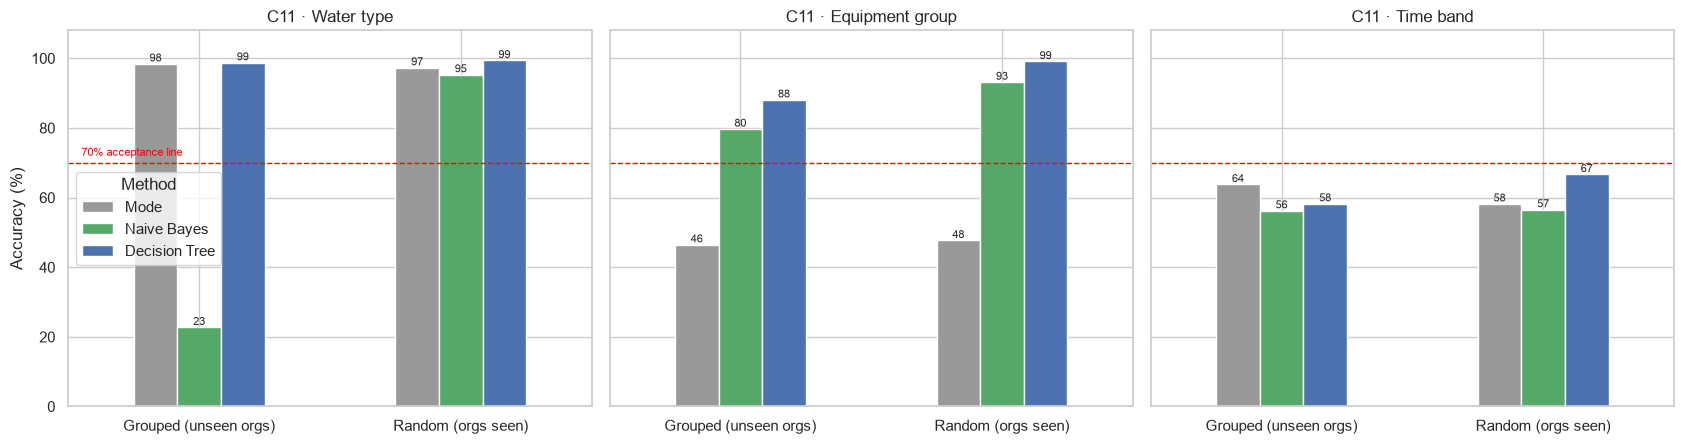

In [11]:
FEATS = {'org': 'org', 'param': 'param', 'act_type': 'act_type', 'value_type': 'value_type', 'state': 'state', 'region': 'region',
         'month': 'month::VARCHAR', 'dow': 'day_of_week', 'has_depth': '(act_depth IS NOT NULL OR res_depth_raw IS NOT NULL)::VARCHAR',
         'is_logger': 'is_logger::VARCHAR', 'has_method': '(coll_method_raw IS NOT NULL)::VARCHAR'}
for k, e in FEATS.items():   # one small lookup table per feature: value -> integer code
    con.execute(f"CREATE OR REPLACE TEMP TABLE d_{k} AS SELECT v, (row_number() OVER (ORDER BY v) - 1)::INT AS c FROM (SELECT DISTINCT coalesce({e}, 'NA') AS v FROM v8)")
sel = ', '.join(f'd_{k}.c AS {k}' for k in FEATS)
joins = ' '.join(f"JOIN d_{k} ON d_{k}.v = coalesce({e}, 'NA')" for k, e in FEATS.items())
X_all = q(f'''SELECT rid, {sel}, water_type_l1, equipment_l1, time_band_l1, is_summary FROM v8 {joins}''').sort_values('rid').reset_index(drop=True)
FCOLS = list(FEATS)
for c in FCOLS: X_all[c] = X_all[c].astype('int32')
NCAT = [int(X_all[c].max()) + 1 for c in FCOLS]
print(f'Feature matrix: {X_all.shape[0]:,} rows × {len(FCOLS)} features   ·   categories per feature: {dict(zip(FCOLS, NCAT))}')

TARGETS = {'Water type': 'water_type_l1', 'Equipment group': 'equipment_l1', 'Time band': 'time_band_l1'}
rng = np.random.default_rng(42)
results, models, cms = [], {}, {}
for name, col in TARGETS.items():
    t0 = time.time()
    pool = X_all[X_all[col].notna() & ((name != 'Time band') | (X_all[col] != 'Whole day'))]
    known = pool.sample(min(400_000, len(pool)), random_state=42)
    y = known[col].astype(str).values; Xk = known[FCOLS].values; orgk = known['org'].values
    # random split
    te = rng.random(len(known)) < 0.2
    # grouped split: hold out ~20% of organizations
    orgs = np.unique(orgk); hold = set(rng.choice(orgs, size=max(1, int(len(orgs) * 0.2)), replace=False))
    gte = np.isin(orgk, list(hold))
    for split, mask in [('Random (orgs seen)', te), ('Grouped (unseen orgs)', gte)]:
        Xtr, ytr, Xte, yte = Xk[~mask], y[~mask], Xk[mask], y[mask]
        mode_val = pd.Series(ytr).mode()[0]
        preds = {'Mode': np.full(len(yte), mode_val)}
        dt = DecisionTreeClassifier(max_depth=15, min_samples_leaf=50, random_state=42).fit(Xtr, ytr); preds['Decision Tree'] = dt.predict(Xte)
        nb = CategoricalNB(alpha=1.0, min_categories=NCAT).fit(Xtr, ytr); preds['Naive Bayes'] = nb.predict(Xte)
        for m, pr in preds.items():
            results.append({'Field': name, 'Test': split, 'Method': m, 'Accuracy': accuracy_score(yte, pr),
                            'Macro-F1': f1_score(yte, pr, average='macro', zero_division=0), 'Test rows': len(yte), 'Classes': len(set(y))})
        if split == 'Random (orgs seen)':
            labels = sorted(set(y)); cms[name] = (labels, confusion_matrix(yte, preds['Decision Tree'], labels=labels))
    # final models trained on all known sample rows
    models[name] = {'Decision Tree': DecisionTreeClassifier(max_depth=15, min_samples_leaf=50, random_state=42).fit(Xk, y),
                    'Naive Bayes': CategoricalNB(alpha=1.0, min_categories=NCAT).fit(Xk, y), 'Mode': pd.Series(y).mode()[0]}
    print(f'{name}: trained/evaluated on {len(known):,} known rows in {time.time() - t0:.0f}s')
res = pd.DataFrame(results)
display(save_tab(res.round(4), '11_imputation_comparison'))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), sharey=True)
for ax, name in zip(axes, TARGETS):
    d = res[res.Field == name].pivot(index='Test', columns='Method', values='Accuracy')[['Mode', 'Naive Bayes', 'Decision Tree']] * 100
    d.plot(kind='bar', ax=ax, color=['#999999', '#55A868', '#4C72B0'], rot=0, legend=(name == 'Water type'))
    for cont in ax.containers: ax.bar_label(cont, fmt='%.0f', fontsize=8)
    ax.axhline(70, color='red', ls='--', lw=1); ax.set(title=f'C11 · {name}', ylabel='Accuracy (%)', xlabel='', ylim=(0, 108))
axes[0].text(-0.45, 72, '70% acceptance line', color='red', fontsize=8)
save_fig('11_imputation_comparison')

**Why this chart:** for each field, the three methods are compared on both tests. The red line is the pre-set 70% acceptance bar, so the chart shows directly which method qualifies, and on which kind of rows.

**🔎 Inference (C11): Decision Tree vs Naive Bayes vs mode**
- **The Decision Tree wins every comparison**, but *winning* is not enough. It must also beat the simple mode guess by a clear margin, and the results differ sharply by field:
  - **Equipment group (4 classes): clear success.**
    - Random test: tree **99.1%** vs mode 47.7%, macro-F1 0.89.
    - Grouped test (organizations never seen): tree **88.1%** vs mode 46.5%.
    - Naive Bayes is good too (93.2% / 79.7%), but lower.
  - **Water type: the model is accurate, but it adds almost nothing.** The tree is 99.4% / 98.8% accurate, but **the mode ("Surface Water") is already 97.3% / 98.4%**. Known water types are overwhelmingly surface water, so "accuracy" is high for any method. Macro-F1 shows the tree is better at the rare classes (0.49 vs 0.14), but the overall gain is only **+2.1 and +0.3 points**.
  - **Time band: not good enough.** The tree reaches **66.6%** on the random test (below the 70% bar). On unseen organizations it is **worse than the mode** (58.3% vs 63.8%), because the time of day depends on each organization's habits, which cannot be learned for an organization never seen.
- **Naive Bayes collapses on unseen organizations for water type (22.7%).** Because it assumes clues are independent, an unseen organization's "zero evidence" distorts its probabilities. The tree simply falls back on the other clues. That is a concrete, data-backed reason to prefer the tree here.
- **Why two tests matter:** the grouped test is the honest one for the 352K–3.3M rows from organizations that **never** record a field. A random test alone would have overstated quality, for example for time band.

### 11b · Apply the decision rule
For each field the rows still missing are split into: rows from organizations that **sometimes** fill the field (judged by the *random* test) and rows from organizations that **never** fill it (judged by the *grouped* test). The best model is applied to a group only if it passes the rule for that group.

,Field,Rows group,Rows,Best model,Accuracy,Gain over mode,Decision
0,Water type,orgs that sometimes fill it,178000,Decision Tree,0.994,0.021,Not Reported
1,Water type,orgs that never fill it,3286180,Decision Tree,0.988,0.003,Not Reported
2,Equipment group,orgs that sometimes fill it,2331599,Decision Tree,0.991,0.514,Impute with Decision Tree
3,Equipment group,orgs that never fill it,352134,Decision Tree,0.881,0.416,Impute with Decision Tree
4,Time band,orgs that sometimes fill it,998712,Decision Tree,0.666,0.084,Not Reported
5,Time band,orgs that never fill it,84798,Decision Tree,0.582,-0.055,Not Reported


rows in curated table: 4958238


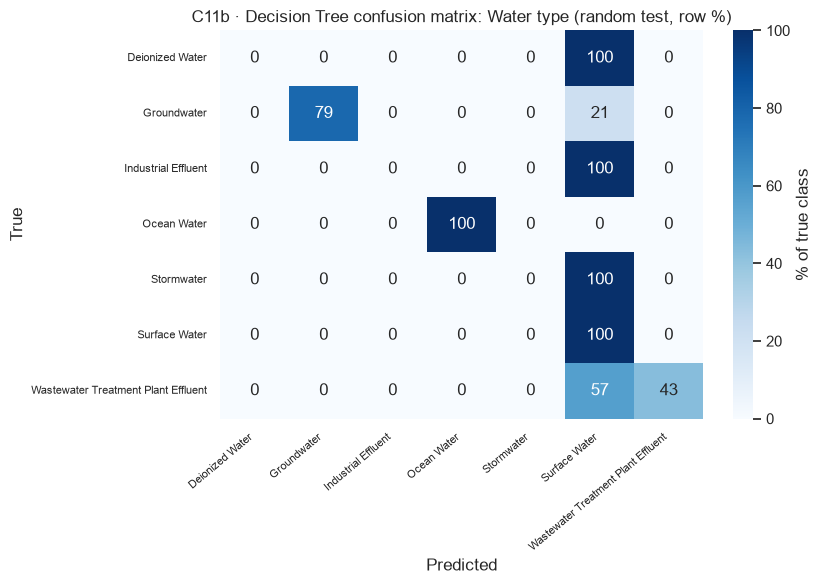

In [12]:
decisions, fills = [], []
for name, col in TARGETS.items():
    src = {'Water type': 'water_type', 'Equipment group': 'equipment', 'Time band': 'time_band'}[name]
    miss = X_all[X_all[col].isna()]
    if len(miss) == 0: continue
    org_known = set(X_all.loc[X_all[col].notna(), 'org'].unique())
    seen = miss.org.isin(org_known).values
    for grp, mask, test in [('orgs that sometimes fill it', seen, 'Random (orgs seen)'), ('orgs that never fill it', ~seen, 'Grouped (unseen orgs)')]:
        r = res[(res.Field == name) & (res.Test == test)].set_index('Method')
        best = r.loc[['Decision Tree', 'Naive Bayes'], 'Accuracy'].idxmax()
        acc, gain = r.loc[best, 'Accuracy'], r.loc[best, 'Accuracy'] - r.loc['Mode', 'Accuracy']
        accept = (acc >= 0.70) and (gain >= 0.10)
        decisions.append({'Field': name, 'Rows group': grp, 'Rows': int(mask.sum()), 'Best model': best, 'Accuracy': round(acc, 3),
                          'Gain over mode': round(gain, 3), 'Decision': f'Impute with {best}' if accept else 'Not Reported'})
        if mask.sum() == 0: continue
        idx = miss.index[mask]
        if accept:
            pred = models[name][best].predict(X_all.loc[idx, FCOLS].values)
            fills.append(pd.DataFrame({'rid': X_all.loc[idx, 'rid'].values, 'field': src, 'value': pred, 'src': f'Model: {best}'}))
        else:
            fills.append(pd.DataFrame({'rid': X_all.loc[idx, 'rid'].values, 'field': src, 'value': 'Not Reported', 'src': 'Not Reported'}))
dec = pd.DataFrame(decisions); display(save_tab(dec, '11_imputation_decisions'))
fill = pd.concat(fills, ignore_index=True)
for f in ['water_type', 'equipment', 'time_band']:
    con.register('f_df', fill[fill.field == f][['rid', 'value', 'src']])
    con.execute(f'CREATE OR REPLACE TABLE fill_{f} AS SELECT * FROM f_df')
con.execute('''
CREATE OR REPLACE TABLE cur AS SELECT v8.*,
  coalesce(water_type_l1, fw.value) AS water_type, coalesce(water_type_src, fw.src) AS water_type_source,
  coalesce(equipment_l1, fe.value) AS equipment_group, coalesce(equipment_src, fe.src) AS equipment_source,
  coalesce(time_band_l1, ft.value) AS time_band, coalesce(time_band_src, ft.src) AS time_band_source
FROM v8 LEFT JOIN fill_water_type fw USING (rid) LEFT JOIN fill_equipment fe USING (rid) LEFT JOIN fill_time_band ft USING (rid)''')
con.execute('DROP TABLE v8')
print('rows in curated table:', q('SELECT count(*) n FROM cur').n[0])

name = 'Water type'; labels, cm = cms[name]
cmn = cm / cm.sum(axis=1, keepdims=True).clip(min=1) * 100
keep = cm.sum(axis=1) > 0
fig, ax = plt.subplots(figsize=(8.5, 6))
sns.heatmap(cmn[np.ix_(keep, keep)], annot=True, fmt='.0f', cmap='Blues', xticklabels=np.array(labels)[keep], yticklabels=np.array(labels)[keep], ax=ax, cbar_kws={'label': '% of true class'})
ax.set(title='C11b · Decision Tree confusion matrix: Water type (random test, row %)', xlabel='Predicted', ylabel='True')
plt.setp(ax.get_xticklabels(), rotation=40, ha='right', fontsize=8); plt.setp(ax.get_yticklabels(), fontsize=8)
save_fig('11b_confusion_water_type')

**Why this chart:** accuracy alone can hide a model that just predicts the common class. The confusion matrix shows, for each true water type, what the tree predicted; a strong diagonal means each class is recognised, not just the largest one.

**🔎 Inference (C11b): confusion matrix, water type**
- **Surface Water** (the dominant class) is recognised almost perfectly, and rows of the large minority classes (Groundwater, Ocean Water) are mostly correct too.
- Very small classes (e.g. stormwater, effluents) are often predicted as Surface Water. That is why **macro-F1 (0.49) is far below accuracy (99%)**: the overall accuracy is driven by the big class.
- **Decision applied:** although the tree is 98–99% accurate, it beats the mode by only 0.3–2.1 points, below the pre-set +10 rule. So the missing water types are honestly marked **"Not Reported"** rather than filled with a near-certain but low-value guess. In analysis, **water type is reported only where it is known** (30% of rows), and known values are 97% surface water.

## 12 · Missing-value summary: before → after
For each treated field: how many rows were missing at the start, and how they were resolved (original value, rule, model, or Not Reported).

source,Original,Rule: same site,Rule: parameter definition,Rule: summary = whole day,Model: Decision Tree,Not Reported
Field,,,,,,
Collection method,37.11,0.00,0.00,0.00,0.00,62.89
Equipment group,45.87,0.00,0.00,0.00,54.13,0.00
Sample fraction,41.62,0.00,58.38,0.00,0.00,0.00
Time band,59.57,0.00,0.00,18.58,0.00,21.85
Water type,21.96,8.17,0.00,0.00,0.00,69.87


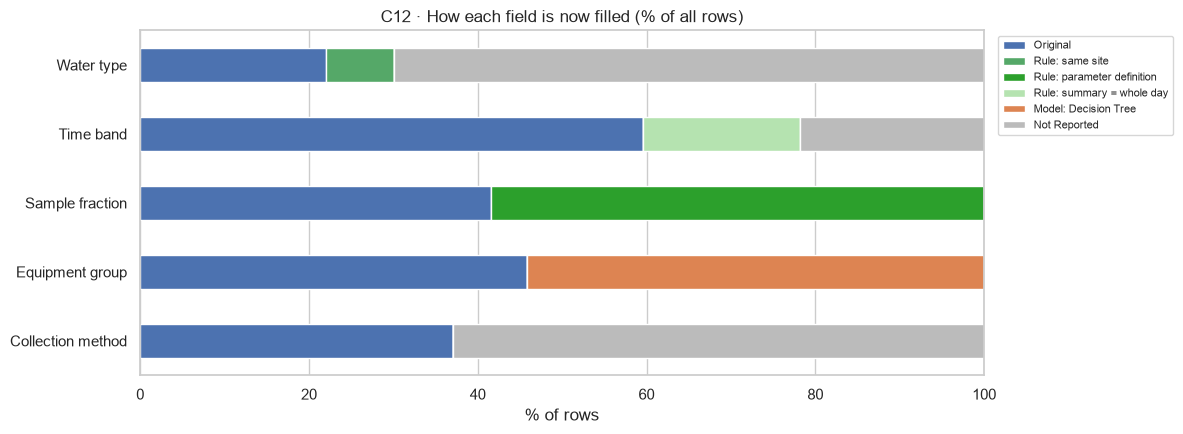

In [13]:
srcs = []
for f, col in [('Water type', 'water_type_source'), ('Equipment group', 'equipment_source'), ('Time band', 'time_band_source'),
               ('Sample fraction', 'sample_fraction_src'), ('Collection method', 'collection_method_src')]:
    d = q(f"SELECT coalesce({col}, 'Still missing') AS source, count(*) n FROM cur GROUP BY 1"); d['Field'] = f; srcs.append(d)
srcs = pd.concat(srcs); srcs['pct'] = (srcs.n / N_RAW * 100).round(2)
sp = srcs.pivot_table(index='Field', columns='source', values='pct', fill_value=0)
order = [c for c in ['Original', 'Rule: same site', 'Rule: same activity', 'Rule: parameter definition', 'Rule: summary = whole day',
                     'Model: Decision Tree', 'Model: Naive Bayes', 'Not Reported', 'Still missing'] if c in sp]
sp = sp[order]; display(save_tab(sp.round(2), '12_missing_resolution', index=True))
colors = {'Original': '#4C72B0', 'Rule: same site': '#55A868', 'Rule: same activity': '#8fd19e', 'Rule: parameter definition': '#2ca02c',
          'Rule: summary = whole day': '#b5e3b0', 'Model: Decision Tree': '#DD8452', 'Model: Naive Bayes': '#f2b880', 'Not Reported': '#bbbbbb', 'Still missing': '#C44E52'}
ax = sp.plot(kind='barh', stacked=True, figsize=(12, 4.5), color=[colors[c] for c in sp.columns])
ax.set(title='C12 · How each field is now filled (% of all rows)', xlabel='% of rows', ylabel=''); ax.legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc='upper left')
save_fig('12_missing_resolution')

**Why this chart:** one bar per field, split by *where its value came from*. The blue part is original data, greens are rules, oranges are model predictions and grey is honestly left as Not Reported, which is the full audit trail at a glance.

**🔎 Inference (C12): how every field is now filled**
- **Equipment group is now complete:** 45.9% original + **54.1% predicted by the Decision Tree**, accepted because it passed both tests (99% / 88%). Every predicted value is labelled `Model: Decision Tree` in `equipment_source`.
- **Sample fraction is complete:** 41.6% original + 58.4% by the parameter-definition rule.
- **Time band:** 59.6% original + 18.6% *Whole day* (rule) + **21.9% Not Reported**. The model was below the 70% bar, so it was not used.
- **Water type:** 22.0% original + 8.2% by the same-site rule + **69.9% Not Reported** (the model gain over the mode was too small).
- **Collection method:** 37.1% original + 62.9% Not Reported.
- **Impact:** the result is a **mix of three methods chosen field by field from evidence**, not one blanket fill. This is exactly the faculty's requirement: rule-based where certain, Decision Tree where it proved accurate, and an honest *Not Reported* where neither was good enough. Nothing original was overwritten, and every filled value carries its source.

## 13 · Before vs after cleaning
The same statistics as Step 1 (section 10), recomputed on **analysis-ready rows in standard units**. If cleaning worked, the means should move close to the medians and the absurd maximums and skewness should disappear.

Before (raw, main unit)                                       After (curated, standard unit)                                     
                                       n     mean  median         max skewness                              n     mean  median        max skewness
Parameter                                                                                                                                         
Temperature                    1971361.0    15.64   15.42    25430.00   589.27                      1912387.0    16.98   17.30      49.80    -0.25
Dissolved oxygen                762330.0    17.03    8.11  6936396.00   873.11                       690164.0     7.62    8.01      25.00    -0.49
pH                              703799.0     7.74    7.80     8325.00   507.97                       658268.0     7.65    7.76      13.96    -1.11
Turbidity                       345949.0    34.13    4.20    97225.28    72.78                       336418.0    33.69    4.32    9733.91    16.73
Conductivity                    140631.0  1814.41  109.00   220591.00     5.38                       131417.0  2022.36  107.30  196876.59     6.73
Nitrate                          42557.0     1.84    0.45      225.00     4.12                        43379.0     1.75    0.40      98.80     7.65

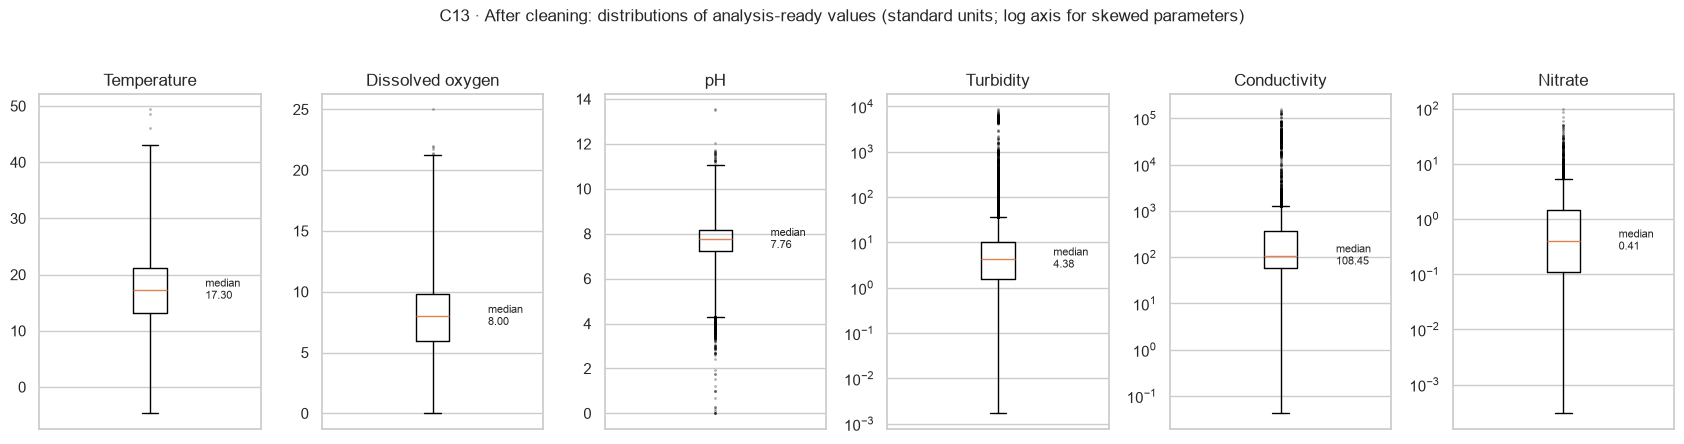

In [14]:
prof = pd.read_csv(TAB / 'P10_raw_numeric_summary.csv').set_index('Parameter')
aft = []
for p in PARAMS:
    r = q(f'''SELECT count(*) n, avg(value_std) mean, median(value_std) median, stddev(value_std) std, min(value_std) min, max(value_std) max,
                     skewness(value_std) skewness FROM cur WHERE analysis_ready AND param = '{p}' ''').iloc[0]
    aft.append({'Parameter': SHORT[p], **r.to_dict()})
aft = pd.DataFrame(aft).set_index('Parameter')
cmp_ = pd.concat({'Before (raw, main unit)': prof[['n', 'mean', 'median', 'max', 'skewness']],
                  'After (curated, standard unit)': aft[['n', 'mean', 'median', 'max', 'skewness']]}, axis=1)
display(save_tab(cmp_.round(2), '13_before_after_stats', index=True))
samp = q('''SELECT param, value_std FROM (SELECT param, value_std FROM cur WHERE analysis_ready) USING SAMPLE reservoir(400000 ROWS) REPEATABLE (7)''')
fig, axes = plt.subplots(1, 6, figsize=(17, 4.3))
for ax, p in zip(axes, PARAMS):
    s = samp[samp.param == p].value_std
    if p in LOGP: s = s[s > 0]; ax.set_yscale('log')
    ax.boxplot(s, whis=3, flierprops=dict(marker='.', markersize=2, alpha=0.3)); ax.set(title=SHORT[p], xticks=[])
    ax.text(1.25, s.median(), f'median\n{s.median():.2f}', fontsize=8, va='center')
fig.suptitle('C13 · After cleaning: distributions of analysis-ready values (standard units; log axis for skewed parameters)', y=1.03, fontsize=12)
save_fig('13_after_boxplots')

**🔎 Inference (C13): before vs after cleaning**
- **Means now match medians.**
  - **Temperature:** mean 17.0 vs median 17.3 °C; skewness 589 → **-0.25**.
  - **DO:** mean 17.0 → **7.62 mg/L** (median 8.01); maximum 6.9 million → 25.
  - **pH:** maximum 8,325 → **13.96**.
  - These three are now near-symmetric (skewness close to 0), which shows the absurd values were removed.
- **Temperature's median rose from 15.4 to 17.3 °C** because the 885K °F values (mostly summer logger readings) were converted and joined the °C data, and many cold-season daily summaries left the single-reading set.
- **Turbidity, conductivity and nitrate stay right-skewed** (skewness 17, 7, 8). That is their **natural shape**: most water is clear, fresh and low in nitrate, and a few storm, estuary and farm sites are very high. Medians (turbidity 4.3 NTU, conductivity 107 µS/cm, nitrate 0.40 mg/L) are the right summary, with log scales in charts and possibly log transforms in regression.
- **Impact:** the curated data now gives physically sensible statistics, which is the foundation for trustworthy EDA, OLAP and models.

## 14 · Save the curated file and the data-quality report
- **`data/processed/wq_curated.parquet`**: every row (4,958,238), clean columns, flags, derived attributes and the source of every filled value. This is the **only** input for EDA, the warehouse and the models.
- **`C14_data_quality_report.csv`**: the brief's format, *Quality problem · Field · Count · Treatment · Justification*, with counts measured on the final file.

In [15]:
FINAL_COLS = '''rid, result_id, act_id, org, provider, site, state, region, state_match, lat, lon, flip_candidate,
  param, parameter_group, val_raw, unit_raw, speciation, value_std, unit_std, unit_status, censor_limit, detect_cond,
  dt, year, quarter, month, day_of_week, season, tm_raw, time_clean, hour, time_band, time_band_source, time_known, tz, ts_local, ts_utc,
  act_type, sample_type_group, status, value_type, qualifier, stat AS statistic_type, time_basis,
  water_type, water_type_source, equipment_group, equipment_source, collection_method, collection_method_src AS collection_method_source,
  sample_fraction, sample_fraction_src AS sample_fraction_source, act_depth, act_depth_unit, res_depth_raw,
  is_qc, is_rejected, is_suspect, is_provisional, is_summary, is_logger, is_duplicate, is_censored, is_impossible, is_extreme_outlier,
  exclusion_reason, analysis_ready, result_band, exceedance_flag, high_risk_flag'''
OUTF = PROC / 'wq_curated.parquet'
con.execute(f"COPY (SELECT {FINAL_COLS} FROM cur ORDER BY ts_local, rid) TO '{OUTF.as_posix()}' (FORMAT parquet, COMPRESSION zstd, ROW_GROUP_SIZE 500000)")
chk = duckdb.sql(f"SELECT count(*) n, count(DISTINCT result_id) ids, sum(analysis_ready::INT) ready FROM '{OUTF.as_posix()}'").df().iloc[0]
print(f'Saved {OUTF}  ({OUTF.stat().st_size / 1e6:.0f} MB): {int(chk.n):,} rows, {int(chk.ids):,} unique result IDs, {int(chk.ready):,} analysis-ready')

def c(sql): return int(q(f'SELECT count(*) n FROM cur WHERE {sql}').n[0])
dqr = pd.DataFrame([
 ('Exact duplicate', 'all columns', 0, 'None needed', 'Step 1 found 0 identical rows and 0 repeated ResultIdentifiers'),
 ('Duplicate copy (field visit)', 'activity+parameter+fraction+statistic+depths+value+unit', c('is_duplicate'), 'Flag; keep first copy for analysis', 'Same result entered twice in one visit would double-count'),
 ('Summary statistic (other grain)', 'StatisticalBaseCode', c('is_summary'), 'Flag; excluded from single-reading analysis', 'A daily mean/min/max is a different grain from one reading'),
 ('Quality-control record', 'ActivityTypeCode', c('is_qc'), 'Flag; excluded from analysis', 'Tests equipment, not water'),
 ('Rejected result', 'ResultStatusIdentifier', c('is_rejected'), 'Exclude from analysis', 'Refused by the data provider'),
 ('Provisional result', 'ResultStatusIdentifier', c('is_provisional'), 'Retain + flag is_provisional', 'Not rejected; recent data still under review'),
 ('Suspect value', 'MeasureQualifierCode', c('is_suspect'), 'Flag; excluded from analysis', 'Marked suspect by the provider'),
 ("'=' prefix", 'ResultMeasureValue', c("val_raw LIKE '=%' AND val_num IS NOT NULL"), 'Correct (strip =)', 'Formatting slip; the number is valid'),
 ('Censored / non-detect', 'ResultMeasureValue', c('is_censored'), 'Flag; limit kept in censor_limit; excluded from averages', 'Only a bound, not a measurement'),
 ('Missing or text value', 'ResultMeasureValue', c('val_num IS NULL AND NOT is_censored'), 'Not imputed; excluded from numeric analysis', 'Inventing measurements would fake water quality'),
 ('Unit converted', 'ResultMeasure/MeasureUnitCode', c("unit_status = 'Converted'"), 'Convert to standard unit', 'Values must be comparable'),
 ('°F labelled as °C', 'ResultMeasure/MeasureUnitCode', c("unit_status LIKE 'Corrected%'"), 'Correct as °F → °C, flagged', '50–120 °C is impossible for water but normal in °F'),
 ('Unusable unit', 'ResultMeasure/MeasureUnitCode', c("unit_status = 'Unusable' AND val_num IS NOT NULL"), 'Retain; excluded from numeric analysis', 'Unit missing or impossible for the parameter (e.g. pH in mV)'),
 ('DO % saturation', 'ResultMeasure/MeasureUnitCode', c("unit_status LIKE 'Different%'"), 'Kept separately; excluded from mg/L analysis', 'Different measure'),
 ('Physically impossible value', 'ResultMeasureValue', c('is_impossible'), 'Flag; excluded from analysis', 'Outside physical range after standardisation'),
 ('Extreme outlier (3×IQR, log-aware)', 'ResultMeasureValue', c('is_extreme_outlier'), 'Retain + flag', 'May be real events (storms, hypoxia)'),
 ('Missing time of day', 'ActivityStartTime/Time', c('NOT time_known'), 'TimeBand: rule / model / Not Reported; ts_local uses 12:00 with time_known = false', 'Date is valid; only the time is unknown'),
 ('Midnight placeholder (field visit)', 'ActivityStartTime/Time', c("tm_raw = '00:00:00' AND time_clean IS NULL"), 'Treated as unknown time', 'False midnight peak'),
 ('Missing / suspect coordinates', 'Latitude/Longitude', c('lat IS NULL'), "State/Region from site median; else 'Unknown'", 'Location cannot be confirmed'),
 ('Wrong-sign longitude', 'Longitude', c('flip_candidate'), 'Set to missing, listed as flip_candidate', 'True sign cannot be confirmed automatically'),
 ('Missing water type', 'ActivityMediaSubdivisionName', c("water_type_source <> 'Original'"), 'Rule (same site) → model → Not Reported', 'See sections 10–11'),
 ('Missing equipment', 'SampleCollectionEquipmentName', c("equipment_source <> 'Original'"), 'Rule (same activity) → model → Not Reported', 'See sections 10–11'),
 ('Missing sample fraction', 'ResultSampleFractionText', c("sample_fraction_src <> 'Original'"), 'Rule by parameter definition', 'Fraction follows from what the parameter is'),
 ('Missing collection method', 'SampleCollectionMethod/MethodName', c("collection_method_src <> 'Original'"), 'Rule (same activity) else Not Reported', 'Free text too inconsistent to predict'),
], columns=['Quality problem', 'Field', 'Count', 'Treatment', 'Justification'])
dqr['% of rows'] = (dqr.Count / N_RAW * 100).round(3)
display(save_tab(dqr, '14_data_quality_report'))
con.close()
DB.unlink(missing_ok=True)   # the work database is temporary; the Parquet file is the output

Saved L:\0_MITAOE-3rd\SEV- V\EDA\EDA_project\data\processed\wq_curated.parquet  (134 MB): 4,958,238 rows, 4,958,238 unique result IDs, 3,772,033 analysis-ready


,Quality problem,Field,Count,Treatment,Justification,% of rows
0,Exact duplicate,all columns,0,None needed,Step 1 found 0 identical rows and 0 repeated ResultIdentifiers,0.000
1,Duplicate copy (field visit),activity+parameter+fraction+statistic+depths+value+unit,186497,Flag; keep first copy for analysis,Same result entered twice in one visit would double-count,3.761
2,Summary statistic (other grain),StatisticalBaseCode,921023,Flag; excluded from single-reading analysis,A daily mean/min/max is a different grain from one reading,18.576
3,Quality-control record,ActivityTypeCode,29108,Flag; excluded from analysis,"Tests equipment, not water",0.587
4,Rejected result,ResultStatusIdentifier,175,Exclude from analysis,Refused by the data provider,0.004
5,Provisional result,ResultStatusIdentifier,92644,Retain + flag is_provisional,Not rejected; recent data still under review,1.868
6,Suspect value,MeasureQualifierCode,91600,Flag; excluded from analysis,Marked suspect by the provider,1.847
7,'=' prefix,ResultMeasureValue,9708,Correct (strip =),Formatting slip; the number is valid,0.196
8,Censored / non-detect,ResultMeasureValue,14958,Flag; limit kept in censor_limit; excluded from averages,"Only a bound, not a measurement",0.302
9,Missing or text value,ResultMeasureValue,20880,Not imputed; excluded from numeric analysis,Inventing measurements would fake water quality,0.421


**🔎 Inference (C14): curated file and data-quality report**
- **`wq_curated.parquet`** holds all **4,958,238 rows** (unique IDs confirmed), **3,772,033 analysis-ready**, in about 134 MB. It has clean columns, flags, derived attributes and a *source* column for every filled value, and is sorted by event time, ready for the real-time replay.
- The **data-quality report** follows the brief's format: problem, field, count, treatment, justification. Every decision is **attribute-specific** (no "all nulls removed"), and each count matches the Step 1 profiling or the reconciliation.
- **Key messages for the viva:**
  1. Nothing was deleted; everything is flagged and explained.
  2. Unit errors, not bad sensors, caused most "impossible" values.
  3. Daily summaries were separated as a different grain.
  4. Missing labels were treated by **rule → Decision Tree (only where it proved ≥ 70% accurate and +10 points better than the mode) → Not Reported**.
  5. Measured values were **never** imputed.

## Outputs of this notebook
| Output | Use |
|---|---|
| `data/processed/wq_curated.parquet` | Input for Step 3 (EDA), Step 4 (feature selection), Steps 5–8 (warehouses), Step 10 (mining) |
| `tables/C14_data_quality_report.csv` | The brief's data-quality report |
| `tables/C11_imputation_comparison.csv`, `C11_imputation_decisions.csv` | Evidence for the DT vs NB vs mode choice |
| `tables/C08_reconciliation.csv` | Proof that the counts add up |
| `figures/C*.png` | Charts for the report and PPT |